In [1]:
import sys

print(sys.executable)

c:\Users\USER\Documents\ML Project\venv\Scripts\python.exe


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Everything is working!")

Everything is working!


In [3]:
import seaborn as sns
from pathlib import Path

print("Libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

Libraries imported successfully!
Pandas version: 3.1.1
NumPy version: 2.5.5


In [4]:

# Load the original accident dataset

file_path = Path("../data/raw/Accident_dataset_combined.csv")

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [5]:

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Number of rows: 3253
Number of columns: 35


In [6]:

display(df.head())


,Sl No,Accident_Index,Date,Day_of_Week,Time_of_Accident,Accident_Location_A,Accident_Location_A_Chainage_km,Accident_Location_A_Chainage_km_RoadSide,Nature_of_Accident_B1,Nature_of_Accident_B2,Nature_of_Accident_B3,Accident_Severity_C,Classification_of_Accident_C1,Classification_of_Accident_C2,Classification_of_Accident_C3,Causes_D1,Causes_D2,Causes_D3,Causes_D4,Causes_D5,Road_Feature_E,Road_Condition_F,Intersection_Type_G,Weather_Conditions_H,Vehicle_Type_Involved_J_V1,Vehicle_Type_Involved_J_V2,Vehicle_Type_Involved_J_V3,Vehicle_Type_Involved_J_V4,Number_of_Vehicles,Number_of_Casualties_Fatel,Number_of_Casualties_GrievousInjury,Number_of_Casualties_MinorInjury,Number_of_Casualties_NotInjured,Number_of_Casualties,Remarks
0,1,201300001,41518,7,13:00,2,187.6,RHS,8,NaN,NaN,3,9.0,NaN,NaN,2,NaN,NaN,NaN,NaN,2,3.0,9.0,8.0,1,NaN,NaN,NaN,1,NaN,NaN,2.0,NaN,2,NaN
1,2,201300002,41521,3,15:25,2,152.3,LHS,4,NaN,NaN,4,3.0,NaN,NaN,3,NaN,NaN,NaN,NaN,2,6.0,4.0,12.0,5,NaN,NaN,NaN,1,NaN,NaN,NaN,1.0,0,NaN
2,3,201300003,41526,1,00:40,2,177.8,RHS,4,NaN,NaN,4,3.0,NaN,NaN,3,NaN,NaN,NaN,NaN,2,6.0,4.0,12.0,5,NaN,NaN,NaN,1,NaN,NaN,NaN,1.0,0,NaN
3,4,201300004,41528,3,07:30,2,186.8,LHS,8,NaN,NaN,3,9.0,NaN,NaN,2,NaN,NaN,NaN,NaN,2,3.0,9.0,8.0,1,NaN,NaN,NaN,1,NaN,NaN,1.0,NaN,1,NaN
4,5,201300005,41534,2,13:00,2,173.4,LHS,5,NaN,NaN,4,9.0,NaN,NaN,4,NaN,NaN,NaN,NaN,3,4.0,5.0,7.0,1,NaN,NaN,NaN,1,NaN,NaN,NaN,1.0,0,NaN


In [7]:

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 3253 entries, 0 to 3252
Data columns (total 35 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Sl No                                     3253 non-null   int64  
 1   Accident_Index                            3253 non-null   int64  
 2   Date                                      3253 non-null   int64  
 3   Day_of_Week                               3253 non-null   int64  
 4   Time_of_Accident                          3253 non-null   str    
 5   Accident_Location_A                       3253 non-null   int64  
 6   Accident_Location_A_Chainage_km           3253 non-null   str    
 7   Accident_Location_A_Chainage_km_RoadSide  3253 non-null   str    
 8   Nature_of_Accident_B1                     3252 non-null   str    
 9   Nature_of_Accident_B2                     9 non-null      str    
 10  Nature_of_Accident_B3                     1 non

In [8]:

# Check missing values in each column

missing_values = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})

missing_values = missing_values.sort_values(
    by='Missing Percentage',
    ascending=False
)

display(missing_values)


,Missing Values,Missing Percentage
Remarks,3253,100.000000
Causes_D5,3253,100.000000
Nature_of_Accident_B3,3252,99.969259
Vehicle_Type_Involved_J_V4,3252,99.969259
Causes_D4,3249,99.877037
Classification_of_Accident_C3,3248,99.846296
Vehicle_Type_Involved_J_V3,3248,99.846296
Nature_of_Accident_B2,3244,99.723332
Causes_D3,3222,99.047034
Causes_D2,3067,94.282201


In [9]:

# Check the distribution of accident severity

severity_counts = df['Accident_Severity_C'].value_counts().sort_index()

print("Accident Severity Distribution:")
display(severity_counts)

print("\nPercentage Distribution:")

severity_percentage = (
    df['Accident_Severity_C']
    .value_counts(normalize=True)
    .sort_index() * 100
)

display(severity_percentage.round(2))


Accident Severity Distribution:


Accident_Severity_C
1     274
2    1215
3    1251
4     513
Name: count, dtype: int64


Percentage Distribution:


Accident_Severity_C
1     8.42
2    37.35
3    38.46
4    15.77
Name: proportion, dtype: float64

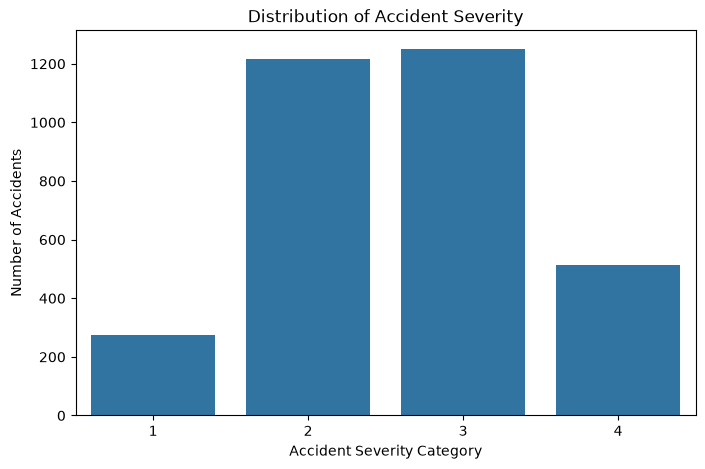

In [10]:

# Visualize accident severity distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Accident_Severity_C',
    order=sorted(df['Accident_Severity_C'].unique())
)

plt.title('Distribution of Accident Severity')
plt.xlabel('Accident Severity Category')
plt.ylabel('Number of Accidents')

plt.show()


In [11]:

# Check unique values in the target variable

print("Unique severity values:")
print(sorted(df['Accident_Severity_C'].unique()))

print("\nNumber of missing target values:")
print(df['Accident_Severity_C'].isnull().sum())

print("\nTarget data type:")
print(df['Accident_Severity_C'].dtype)


Unique severity values:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

Number of missing target values:
0

Target data type:
int64


In [12]:

# Check for completely duplicated rows

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)
print("Total records:", len(df))
print("Unique records:", len(df.drop_duplicates()))


Number of duplicate rows: 0
Total records: 3253
Unique records: 3253


In [13]:

# Check duplicate accident identifiers

duplicate_ids = df['Accident_Index'].duplicated().sum()

print("Duplicate Accident IDs:", duplicate_ids)
print("Unique Accident IDs:", df['Accident_Index'].nunique())


Duplicate Accident IDs: 0
Unique Accident IDs: 3253


In [14]:

# Check serial number uniqueness

print("Unique serial numbers:", df['Sl No'].nunique())
print("Total records:", len(df))


Unique serial numbers: 3253
Total records: 3253


In [15]:

# Inspect the Date column

print("Original Date column:")
display(df['Date'].head(10))

# Convert Excel serial dates into datetime format
converted_dates = pd.to_datetime(
    df['Date'],
    unit='D',
    origin='1899-12-30',
    errors='coerce'
)

print("\nConverted Date column:")
display(converted_dates.head(10))

print("\nEarliest date:", converted_dates.min())
print("Latest date:", converted_dates.max())

print("\nInvalid dates:", converted_dates.isnull().sum())


Original Date column:


0    41518
1    41521
2    41526
3    41528
4    41534
5    41536
6    41536
7    41537
8    41543
9    41544
Name: Date, dtype: int64


Converted Date column:


0   2013-09-01
1   2013-09-04
2   2013-09-09
3   2013-09-11
4   2013-09-17
5   2013-09-19
6   2013-09-19
7   2013-09-20
8   2013-09-26
9   2013-09-27
Name: Date, dtype: datetime64[us]


Earliest date: 2013-01-05 00:00:00
Latest date: 2103-12-24 00:00:00

Invalid dates: 0


In [16]:

# Identify dates outside the expected study period

suspicious_dates = df.loc[
    (converted_dates < '2013-01-01') |
    (converted_dates > '2018-12-31')
].copy()

suspicious_dates['Converted_Date'] = converted_dates[
    suspicious_dates.index
]

print("Number of suspicious date records:",
      len(suspicious_dates))

display(suspicious_dates[
    ['Sl No', 'Accident_Index', 'Date', 'Converted_Date']
])


Number of suspicious date records: 1


,Sl No,Accident_Index,Date,Converted_Date
98,99,201300099,74503,2103-12-24


In [17]:
display(suspicious_dates[
    ['Sl No', 'Accident_Index', 'Date', 'Converted_Date']
])

,Sl No,Accident_Index,Date,Converted_Date
98,99,201300099,74503,2103-12-24


In [18]:
# Count records by year

year_counts = converted_dates.dt.year.value_counts().sort_index()

display(year_counts)

Date
2013     113
2014     274
2015     739
2016     616
2017    1242
2018     268
2103       1
Name: count, dtype: int64

In [19]:

# Inspect records surrounding the suspicious date

nearby_records = df.loc[
    df['Sl No'].between(94, 102),
    ['Sl No', 'Accident_Index', 'Date', 'Day_of_Week',
     'Time_of_Accident', 'Accident_Severity_C']
].copy()

nearby_records['Converted_Date'] = pd.to_datetime(
    nearby_records['Date'],
    unit='D',
    origin='1899-12-30'
)

display(nearby_records)

# Count accidents recorded in each year

year_counts = converted_dates.dt.year.value_counts().sort_index()

display(year_counts)


,Sl No,Accident_Index,Date,Day_of_Week,Time_of_Accident,Accident_Severity_C,Converted_Date
93,94,201300094,41624,1,11:40,2,2013-12-16
94,95,201300095,41626,3,03:30,4,2013-12-18
95,96,201300096,41629,6,10:00,1,2013-12-21
96,97,201300097,41630,7,06:30,2,2013-12-22
97,98,201300098,41631,1,11:10,2,2013-12-23
98,99,201300099,74503,1,01:45,3,2103-12-24
99,100,201300100,41632,2,07:15,3,2013-12-24
100,101,201300101,41634,4,08:32,3,2013-12-26
101,102,201300102,41634,4,11:00,3,2013-12-26


Date
2013     113
2014     274
2015     739
2016     616
2017    1242
2018     268
2103       1
Name: count, dtype: int64

In [20]:
print("Suspicious record:")
display(df.loc[df['Accident_Index'] == 201300099])

print("Weekday of converted date:")
print(converted_dates.loc[df['Accident_Index'] == 201300099].dt.day_name())

Suspicious record:


,Sl No,Accident_Index,Date,Day_of_Week,Time_of_Accident,Accident_Location_A,Accident_Location_A_Chainage_km,Accident_Location_A_Chainage_km_RoadSide,Nature_of_Accident_B1,Nature_of_Accident_B2,Nature_of_Accident_B3,Accident_Severity_C,Classification_of_Accident_C1,Classification_of_Accident_C2,Classification_of_Accident_C3,Causes_D1,Causes_D2,Causes_D3,Causes_D4,Causes_D5,Road_Feature_E,Road_Condition_F,Intersection_Type_G,Weather_Conditions_H,Vehicle_Type_Involved_J_V1,Vehicle_Type_Involved_J_V2,Vehicle_Type_Involved_J_V3,Vehicle_Type_Involved_J_V4,Number_of_Vehicles,Number_of_Casualties_Fatel,Number_of_Casualties_GrievousInjury,Number_of_Casualties_MinorInjury,Number_of_Casualties_NotInjured,Number_of_Casualties,Remarks
98,99,201300099,74503,1,01:45,2,229,RHS,5,NaN,NaN,3,3.0,NaN,NaN,3,NaN,NaN,NaN,NaN,2,2.0,3.0,9.0,1,NaN,NaN,NaN,1,NaN,NaN,3.0,NaN,3,NaN


Weekday of converted date:
98    Monday
Name: Date, dtype: str


In [21]:
# Create a corrected copy of the date column
df['Converted_Date'] = pd.to_datetime(
    df['Date'],
    unit='D',
    origin='1899-12-30',
    errors='coerce'
)

# Correct the suspicious record
df.loc[df['Accident_Index'] == 201300099, 'Converted_Date'] = pd.Timestamp('2013-12-24')

# Verify the correction
display(
    df.loc[
        df['Accident_Index'] == 201300099,
        ['Accident_Index', 'Date', 'Converted_Date']
    ]
)


,Accident_Index,Date,Converted_Date
98,201300099,74503,2013-12-24


In [22]:
# Check the corrected year distribution
year_counts = df['Converted_Date'].dt.year.value_counts().sort_index()

display(year_counts)

print("Total records:", len(df))
print("Missing converted dates:", df['Converted_Date'].isnull().sum())

Converted_Date
2013     114
2014     274
2015     739
2016     616
2017    1242
2018     268
Name: count, dtype: int64

Total records: 3253
Missing converted dates: 0


In [23]:
categorical_columns = df.select_dtypes(include=['object']).columns

for col in categorical_columns:
    print(f"\n{col}")
    print("Unique values:", df[col].nunique())
    print(df[col].unique()[:15])


Time_of_Accident
Unique values: 734
<ArrowStringArray>
['13:00', '15:25', '00:40', '07:30', '10:15', '23:40', '08:15', '22:15',
 '18:25', '06:30', '18:45', '23:00', '17:30', '12:30', '07:15']
Length: 15, dtype: str

Accident_Location_A_Chainage_km
Unique values: 1966
<ArrowStringArray>
['187.6', '152.3', '177.8', '186.8', '173.4', '238.3', '209.6',   '214',
   '226', '178.2', '176.6', '169.9', '198.8', '237.9', '178.5']
Length: 15, dtype: str

Accident_Location_A_Chainage_km_RoadSide
Unique values: 3
<ArrowStringArray>
['RHS', 'LHS', 'LHS ']
Length: 3, dtype: str

Nature_of_Accident_B1
Unique values: 17
<ArrowStringArray>
['8', '4', '5', '6', '2', '7', '1', '3', '9', nan, '7h', '7d', '7b', '7e',
 '7c']
Length: 15, dtype: str

Nature_of_Accident_B2
Unique values: 3
<ArrowStringArray>
[nan, '3', '6', '7d']
Length: 4, dtype: str

Causes_D1
Unique values: 11
<ArrowStringArray>
['2', '3', '4', '1', '5', '8', '6', '5a', '4a', '4f', nan, '4d']
Length: 12, dtype: str

Causes_D2
Unique values:

C:\Users\USER\AppData\Local\Temp\ipykernel_12840\3128132285.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include=['object']).columns


In [24]:
for col in df.select_dtypes(include=['object']).columns:
    original = df[col].dropna().astype(str)
    cleaned = original.str.strip()

    differences = (original != cleaned).sum()

    if differences > 0:
        print(f"{col}: {differences} values have extra whitespace")
        print("Examples:", original[original != cleaned].unique()[:10])

Accident_Location_A_Chainage_km: 1 values have extra whitespace
Examples: <ArrowStringArray>
[' ']
Length: 1, dtype: str
Accident_Location_A_Chainage_km_RoadSide: 13 values have extra whitespace
Examples: <ArrowStringArray>
['LHS ']
Length: 1, dtype: str
Number_of_Casualties_Fatel: 1 values have extra whitespace
Examples: <ArrowStringArray>
[' ']
Length: 1, dtype: str


C:\Users\USER\AppData\Local\Temp\ipykernel_12840\2659842951.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include=['object']).columns:


In [25]:
# Remove leading and trailing whitespace from text columns
for col in df.select_dtypes(include=['str']).columns:
    df[col] = df[col].str.strip()

# Replace empty strings with NaN
df.replace('', np.nan, inplace=True)

print("Whitespace cleaning completed.")

# Verify
print("Blank strings remaining:", (df == '').sum().sum())

Whitespace cleaning completed.
Blank strings remaining: 0


In [26]:
missing_values = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})

missing_values = missing_values[
    missing_values['Missing Values'] > 0
].sort_values(by='Missing Percentage', ascending=False)

display(missing_values)

,Missing Values,Missing Percentage
Causes_D5,3253,100.000000
Remarks,3253,100.000000
Nature_of_Accident_B3,3252,99.969259
Vehicle_Type_Involved_J_V4,3252,99.969259
Causes_D4,3249,99.877037
Classification_of_Accident_C3,3248,99.846296
Vehicle_Type_Involved_J_V3,3248,99.846296
Nature_of_Accident_B2,3244,99.723332
Causes_D3,3222,99.047034
Causes_D2,3067,94.282201


In [27]:
sparse_columns = [
    col for col in df.columns
    if df[col].isnull().mean() > 0.50
]

for col in sparse_columns:
    print(f"\nColumn: {col}")
    print("Non-missing values:", df[col].count())
    print("Unique values:", df[col].nunique())
    print("Sample values:", df[col].dropna().unique()[:15])


Column: Nature_of_Accident_B2
Non-missing values: 9
Unique values: 3
Sample values: <ArrowStringArray>
['3', '6', '7d']
Length: 3, dtype: str

Column: Nature_of_Accident_B3
Non-missing values: 1
Unique values: 1
Sample values: [6.]

Column: Classification_of_Accident_C2
Non-missing values: 241
Unique values: 3
Sample values: [3. 2. 1.]

Column: Classification_of_Accident_C3
Non-missing values: 5
Unique values: 1
Sample values: [3.]

Column: Causes_D2
Non-missing values: 186
Unique values: 7
Sample values: <ArrowStringArray>
['3', '5a', '4a', '2', '1', '4d', '4']
Length: 7, dtype: str

Column: Causes_D3
Non-missing values: 31
Unique values: 6
Sample values: <ArrowStringArray>
['4', '4a', '3', '5a', '4d', '4b']
Length: 6, dtype: str

Column: Causes_D4
Non-missing values: 4
Unique values: 3
Sample values: <ArrowStringArray>
['5a', '4d', '4a']
Length: 3, dtype: str

Column: Causes_D5
Non-missing values: 0
Unique values: 0
Sample values: []

Column: Intersection_Type_G
Non-missing values: 

In [28]:
summary = pd.DataFrame({
    'Non_Missing': df[sparse_columns].count(),
    'Missing_Percentage': df[sparse_columns].isnull().mean() * 100,
    'Unique_Values': df[sparse_columns].nunique(),
    'Most_Common_Values': [
        df[col].value_counts().head(5).to_dict()
        for col in sparse_columns
    ]
})

with pd.option_context('display.max_rows', None, 'display.max_colwidth', None):
    display(summary)

,Non_Missing,Missing_Percentage,Unique_Values,Most_Common_Values
Nature_of_Accident_B2,9,99.723332,3,"{'3': 4, '7d': 3, '6': 2}"
Nature_of_Accident_B3,1,99.969259,1,{6.0: 1}
Classification_of_Accident_C2,241,92.591454,3,"{3.0: 194, 2.0: 46, 1.0: 1}"
Classification_of_Accident_C3,5,99.846296,1,{3.0: 5}
Causes_D2,186,94.282201,7,"{'3': 169, '2': 9, '4a': 3, '4': 2, '5a': 1}"
Causes_D3,31,99.047034,6,"{'4a': 11, '4d': 8, '3': 6, '4': 4, '5a': 1}"
Causes_D4,4,99.877037,3,"{'4a': 2, '5a': 1, '4d': 1}"
Causes_D5,0,100.000000,0,{}
Intersection_Type_G,1384,57.454657,10,"{9.0: 549, 2.0: 282, 1.0: 246, 3.0: 184, 4.0: 74}"
Vehicle_Type_Involved_J_V2,756,76.759914,14,"{5.0: 203, 6.0: 201, 1.0: 170, 9.0: 41, 11.0: 32}"


In [29]:
# Columns to exclude from prediction features
columns_to_exclude = [
    'Sl No',
    'Accident_Index',

    'Nature_of_Accident_B2',
    'Nature_of_Accident_B3',

    'Classification_of_Accident_C2',
    'Classification_of_Accident_C3',

    'Causes_D2',
    'Causes_D3',
    'Causes_D4',
    'Causes_D5',

    'Vehicle_Type_Involved_J_V2',
    'Vehicle_Type_Involved_J_V3',
    'Vehicle_Type_Involved_J_V4',

    'Number_of_Casualties_Fatel',
    'Number_of_Casualties_GrievousInjury',
    'Number_of_Casualties_MinorInjury',
    'Number_of_Casualties_NotInjured',
    'Number_of_Casualties',

    'Remarks'
]

# Display the columns that will remain as candidate features
candidate_features = [
    col for col in df.columns
    if col not in columns_to_exclude
    and col != 'Accident_Severity_C'
]

print("Number of candidate features:", len(candidate_features))
print("\nCandidate features:")
for col in candidate_features:
    print("-", col)

Number of candidate features: 16

Candidate features:
- Date
- Day_of_Week
- Time_of_Accident
- Accident_Location_A
- Accident_Location_A_Chainage_km
- Accident_Location_A_Chainage_km_RoadSide
- Nature_of_Accident_B1
- Classification_of_Accident_C1
- Causes_D1
- Road_Feature_E
- Road_Condition_F
- Intersection_Type_G
- Weather_Conditions_H
- Vehicle_Type_Involved_J_V1
- Number_of_Vehicles
- Converted_Date


In [30]:
candidate_features = [
    'Day_of_Week',
    'Time_of_Accident',
    'Accident_Location_A',
    'Accident_Location_A_Chainage_km',
    'Accident_Location_A_Chainage_km_RoadSide',
    'Nature_of_Accident_B1',
    'Classification_of_Accident_C1',
    'Causes_D1',
    'Road_Feature_E',
    'Road_Condition_F',
    'Intersection_Type_G',
    'Weather_Conditions_H',
    'Vehicle_Type_Involved_J_V1',
    'Number_of_Vehicles',
    'Converted_Date'
]

print("Candidate features:", len(candidate_features))

Candidate features: 15


In [31]:
feature_info = pd.DataFrame({
    'Data_Type': df[candidate_features].dtypes,
    'Missing_Values': df[candidate_features].isnull().sum(),
    'Missing_Percentage': (
        df[candidate_features].isnull().mean() * 100
    ).round(2),
    'Unique_Values': df[candidate_features].nunique()
})

display(feature_info)

,Data_Type,Missing_Values,Missing_Percentage,Unique_Values
Day_of_Week,int64,0,0.00,7
Time_of_Accident,str,0,0.00,734
Accident_Location_A,int64,0,0.00,2
Accident_Location_A_Chainage_km,str,1,0.03,1965
Accident_Location_A_Chainage_km_RoadSide,str,0,0.00,2
Nature_of_Accident_B1,str,1,0.03,17
Classification_of_Accident_C1,float64,1,0.03,8
Causes_D1,str,1,0.03,11
Road_Feature_E,int64,0,0.00,6
Road_Condition_F,float64,1,0.03,8


In [32]:
# Compare intersection information with road features
intersection_check = pd.crosstab(
    df['Road_Feature_E'],
    df['Intersection_Type_G'].isnull(),
    margins=True
)

intersection_check.columns = [
    'Intersection Recorded',
    'Intersection Missing',
    'Total'
]

display(intersection_check)

,Intersection Recorded,Intersection Missing,Total
Road_Feature_E,,,
1,27,2,29
2,594,1,595
3,4,0,4
4,757,1866,2623
5,1,0,1
9,1,0,1
All,1384,1869,3253


In [33]:
intersection_severity = pd.crosstab(
    df['Intersection_Type_G'].isnull(),
    df['Accident_Severity_C'],
    normalize='index'
) * 100

intersection_severity.index = [
    'Intersection Recorded',
    'Intersection Missing'
]

display(intersection_severity.round(2))

Accident_Severity_C,1,2,3,4
Intersection Recorded,8.67,30.85,37.21,23.27
Intersection Missing,8.24,42.16,39.38,10.22


In [34]:
print("Intersection type distribution:")
print(df['Intersection_Type_G'].value_counts(dropna=False).sort_index())

print("\nIntersection types by road feature:")
display(pd.crosstab(
    df['Road_Feature_E'],
    df['Intersection_Type_G'],
    dropna=False
))

Intersection type distribution:
Intersection_Type_G
1.0      246
2.0      282
3.0      184
4.0       74
5.0       36
6.0        6
7.0        5
8.0        1
9.0      549
10.0       1
NaN     1869
Name: count, dtype: int64

Intersection types by road feature:


Intersection_Type_G,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0,NaN
Road_Feature_E,,,,,,,,,,,
1,6,4,1,2,0,0,0,0,14,0,2
2,114,157,98,28,23,5,5,1,162,1,1
3,0,2,0,0,1,0,0,0,1,0,0
4,126,119,85,44,12,1,0,0,370,0,1866
5,0,0,0,0,0,0,0,0,1,0,0
9,0,0,0,0,0,0,0,0,1,0,0


In [35]:
print("Intersection types:")
print(df['Intersection_Type_G'].value_counts(dropna=False).sort_index())

print("\nRoad features:")
print(df['Road_Feature_E'].value_counts(dropna=False).sort_index())

print("\nRoad conditions:")
print(df['Road_Condition_F'].value_counts(dropna=False).sort_index())

Intersection types:
Intersection_Type_G
1.0      246
2.0      282
3.0      184
4.0       74
5.0       36
6.0        6
7.0        5
8.0        1
9.0      549
10.0       1
NaN     1869
Name: count, dtype: int64

Road features:
Road_Feature_E
1      29
2     595
3       4
4    2623
5       1
9       1
Name: count, dtype: int64

Road conditions:
Road_Condition_F
1.0    2594
2.0     285
3.0      72
4.0     245
5.0      18
6.0      15
7.0       6
8.0      17
NaN       1
Name: count, dtype: int64


In [36]:
for col in candidate_features:
    if col not in ['Time_of_Accident', 'Converted_Date',
                   'Accident_Location_A_Chainage_km']:
        print(f"\n{col}")
        print(df[col].value_counts(dropna=False).sort_index())


Day_of_Week
Day_of_Week
1    436
2    428
3    439
4    492
5    472
6    517
7    469
Name: count, dtype: int64

Accident_Location_A
Accident_Location_A
1     511
2    2742
Name: count, dtype: int64

Accident_Location_A_Chainage_km_RoadSide
Accident_Location_A_Chainage_km_RoadSide
LHS    1615
RHS    1638
Name: count, dtype: int64

Nature_of_Accident_B1
Nature_of_Accident_B1
1      844
2      349
3      579
4      125
5       59
6      534
7       10
7a      41
7b     205
7c      36
7d     325
7e       6
7f       4
7g       3
7h      77
8       48
9        7
NaN      1
Name: count, dtype: int64

Classification_of_Accident_C1
Classification_of_Accident_C1
0.0       2
1.0     284
2.0    1205
3.0    1250
4.0     499
5.0       3
8.0       1
9.0       8
NaN       1
Name: count, dtype: int64

Causes_D1
Causes_D1
1       214
2      1433
3      1321
4       241
4a       11
4d        1
4f        1
5        15
5a       12
6         1
8         2
NaN       1
Name: count, dtype: int64

Road_Featu

In [37]:
pd.crosstab(
    df['Classification_of_Accident_C1'],
    df['Accident_Severity_C'],
    margins=True,
    dropna=False
)

Accident_Severity_C,1,2,3,4,All
Classification_of_Accident_C1,,,,,
0.0,0,0,0,2,2
1.0,268,12,4,0,284
2.0,4,1186,10,5,1205
3.0,1,14,1229,6,1250
4.0,0,1,2,496,499
5.0,0,2,0,1,3
8.0,1,0,0,0,1
9.0,0,0,6,2,8
NaN,0,0,0,1,1


In [38]:
candidate_features = [
    'Day_of_Week',
    'Time_of_Accident',
    'Accident_Location_A',
    'Accident_Location_A_Chainage_km',
    'Accident_Location_A_Chainage_km_RoadSide',
    'Nature_of_Accident_B1',
    'Causes_D1',
    'Road_Feature_E',
    'Road_Condition_F',
    'Intersection_Type_G',
    'Weather_Conditions_H',
    'Vehicle_Type_Involved_J_V1',
    'Number_of_Vehicles',
    'Converted_Date'
]

print("Number of candidate features:", len(candidate_features))

Number of candidate features: 14


In [39]:
categorical_columns = [
    'Nature_of_Accident_B1',
    'Causes_D1',
    'Road_Condition_F',
    'Weather_Conditions_H',
    'Vehicle_Type_Involved_J_V1',
    'Intersection_Type_G',
    'Road_Feature_E'
]

for col in categorical_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).sort_index())


--- Nature_of_Accident_B1 ---
Nature_of_Accident_B1
1      844
2      349
3      579
4      125
5       59
6      534
7       10
7a      41
7b     205
7c      36
7d     325
7e       6
7f       4
7g       3
7h      77
8       48
9        7
NaN      1
Name: count, dtype: int64

--- Causes_D1 ---
Causes_D1
1       214
2      1433
3      1321
4       241
4a       11
4d        1
4f        1
5        15
5a       12
6         1
8         2
NaN       1
Name: count, dtype: int64

--- Road_Condition_F ---
Road_Condition_F
1.0    2594
2.0     285
3.0      72
4.0     245
5.0      18
6.0      15
7.0       6
8.0      17
NaN       1
Name: count, dtype: int64

--- Weather_Conditions_H ---
Weather_Conditions_H
1.0     1892
2.0      593
3.0      217
4.0       90
5.0       11
6.0        1
7.0        7
8.0       48
9.0       95
10.0     220
11.0      33
12.0      24
NaN       22
Name: count, dtype: int64

--- Vehicle_Type_Involved_J_V1 ---
Vehicle_Type_Involved_J_V1
1     680
2      20
3      91
4      1

In [40]:
print("Nature of Accident - Unusual code 7")
print(pd.crosstab(
    df['Nature_of_Accident_B1'],
    df['Accident_Severity_C']
).loc[['7']])

print("\nCauses - Unusual codes")
print(pd.crosstab(
    df['Causes_D1'],
    df['Accident_Severity_C']
).loc[['4', '5', '6', '8']])

Nature of Accident - Unusual code 7
Accident_Severity_C    1  2  3  4
Nature_of_Accident_B1            
7                      3  1  0  6

Causes - Unusual codes


Accident_Severity_C   1   2   3   4
Causes_D1                          
4                    30  77  70  64
5                     1   8   3   3
6                     0   0   1   0
8                     0   1   0   1


In [41]:
print("Time format:")
print(df['Time_of_Accident'].head(10))

print("\nEarliest time:", df['Time_of_Accident'].min())
print("Latest time:", df['Time_of_Accident'].max())

print("\nMissing times:", df['Time_of_Accident'].isna().sum())

Time format:
0    13:00
1    15:25
2    00:40
3    07:30
4    13:00
5    10:15
6    23:40
7    08:15
8    22:15
9    18:25
Name: Time_of_Accident, dtype: str

Earliest time: 00:00
Latest time: 23:55

Missing times: 0


In [42]:
# Convert accident time into datetime format
time_values = pd.to_datetime(
    df['Time_of_Accident'],
    format='%H:%M'
)

# Extract hour
df['Accident_Hour'] = time_values.dt.hour

# Divide accidents into four time periods
def get_accident_period(hour):
    if 5 <= hour < 12:
        return 'Morning'
    elif 12 <= hour < 17:
        return 'Afternoon'
    elif 17 <= hour < 21:
        return 'Evening'
    else:
        return 'Night'

df['Accident_Period'] = df['Accident_Hour'].apply(get_accident_period)

print("Accident hour distribution:")
print(df['Accident_Hour'].value_counts().sort_index())

print("\nAccident period distribution:")
print(df['Accident_Period'].value_counts())

Accident hour distribution:
Accident_Hour
0     143
1     126
2      85
3      86
4     105
5     153
6     117
7     127
8     128
9     135
10    146
11    156
12    144
13    126
14    119
15    125
16    146
17    150
18    142
19    194
20    155
21    137
22    149
23    159
Name: count, dtype: int64

Accident period distribution:
Accident_Period
Night        990
Morning      962
Afternoon    660
Evening      641
Name: count, dtype: int64


In [43]:
# Extract year and month
df['Accident_Year'] = df['Converted_Date'].dt.year
df['Accident_Month'] = df['Converted_Date'].dt.month

# Display distributions
print("Accidents by year:")
print(df['Accident_Year'].value_counts().sort_index())

print("\nAccidents by month:")
print(df['Accident_Month'].value_counts().sort_index())

print("\nDate feature missing values:")
print(df[['Accident_Year', 'Accident_Month']].isnull().sum())

Accidents by year:
Accident_Year
2013     114
2014     274
2015     739
2016     616
2017    1242
2018     268
Name: count, dtype: int64

Accidents by month:
Accident_Month
1     306
2     222
3     285
4     319
5     345
6     311
7     222
8     203
9     240
10    271
11    254
12    275
Name: count, dtype: int64

Date feature missing values:
Accident_Year     0
Accident_Month    0
dtype: int64


In [44]:
# Calculate weekday from the converted date
calculated_weekday = (df['Converted_Date'].dt.dayofweek + 1) % 7 + 1

# Compare with the original weekday column
weekday_mismatches = df[
    calculated_weekday != df['Day_of_Week']
][['Accident_Index', 'Converted_Date', 'Day_of_Week']].copy()

weekday_mismatches['Calculated_Weekday'] = calculated_weekday[
    calculated_weekday != df['Day_of_Week']
]

print("Total weekday mismatches:", len(weekday_mismatches))
print("\nMismatched records:")
print(weekday_mismatches.head(20))

Total weekday mismatches: 3253

Mismatched records:
    Accident_Index Converted_Date  Day_of_Week  Calculated_Weekday
0        201300001     2013-09-01            7                   1
1        201300002     2013-09-04            3                   4
2        201300003     2013-09-09            1                   2
3        201300004     2013-09-11            3                   4
4        201300005     2013-09-17            2                   3
5        201300006     2013-09-19            4                   5
6        201300007     2013-09-19            4                   5
7        201300008     2013-09-20            5                   6
8        201300009     2013-09-26            4                   5
9        201300010     2013-09-27            5                   6
10       201300011     2013-09-29            7                   1
11       201300012     2013-09-30            1                   2
12       201300013     2013-10-01            2                   3
13       2

C:\Users\USER\AppData\Local\Temp\ipykernel_12840\3267801243.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  calculated_weekday = (df['Converted_Date'].dt.dayofweek + 1) % 7 + 1


In [45]:
calculated_weekday = df['Converted_Date'].dt.day_of_week + 1

weekday_mismatches = df[
    calculated_weekday != df['Day_of_Week']
][['Accident_Index', 'Converted_Date', 'Day_of_Week']].copy()

weekday_mismatches['Calculated_Weekday'] = calculated_weekday[
    calculated_weekday != df['Day_of_Week']
]

print("Total weekday mismatches:", len(weekday_mismatches))
print(weekday_mismatches.head(20))

Total weekday mismatches: 2
      Accident_Index Converted_Date  Day_of_Week  Calculated_Weekday
98         201300099     2013-12-24            1                   2
1209       201800080     2018-03-24            2                   6


In [46]:
# Inspect records around both mismatches
for accident_id in [201300099, 201800080]:
    print(f"\nRecords around {accident_id}:")

    idx = df.index[df['Accident_Index'] == accident_id][0]

    print(
        df.loc[max(0, idx-3):idx+3, [
            'Sl No',
            'Accident_Index',
            'Date',
            'Converted_Date',
            'Day_of_Week'
        ]].to_string(index=False)
    )


Records around 201300099:
 Sl No  Accident_Index  Date Converted_Date  Day_of_Week
    96       201300096 41629     2013-12-21            6
    97       201300097 41630     2013-12-22            7
    98       201300098 41631     2013-12-23            1
    99       201300099 74503     2013-12-24            1
   100       201300100 41632     2013-12-24            2
   101       201300101 41634     2013-12-26            4
   102       201300102 41634     2013-12-26            4

Records around 201800080:
 Sl No  Accident_Index  Date Converted_Date  Day_of_Week
  1211       201800077 43182     2018-03-23            5
  1212       201800078 43183     2018-03-24            6
  1213       201800079 43183     2018-03-24            6
  1214       201800080 43183     2018-03-24            2
  1215       201800081 43184     2018-03-25            7
  1216       201800082 43184     2018-03-25            7
  1217       201800083 43187     2018-03-28            3


In [47]:
# Correct the suspicious date for accident 201300099
df.loc[
    df['Accident_Index'] == 201300099,
    'Converted_Date'
] = pd.Timestamp('2013-12-23')

# Correct the weekday for accident 201800080
df.loc[
    df['Accident_Index'] == 201800080,
    'Day_of_Week'
] = 6

# Verify both records
print(df[df['Accident_Index'].isin([
    201300099, 201800080
])][[
    'Accident_Index',
    'Date',
    'Converted_Date',
    'Day_of_Week'
]])

      Accident_Index   Date Converted_Date  Day_of_Week
98         201300099  74503     2013-12-23            1
1209       201800080  43183     2018-03-24            6


In [48]:
calculated_weekday = df['Converted_Date'].dt.day_of_week + 1

mismatch_count = (
    calculated_weekday != df['Day_of_Week']
).sum()

print("Total weekday mismatches:", mismatch_count)
print("Total records checked:", len(df))

Total weekday mismatches: 0
Total records checked: 3253


Exploratory Data Analysis (EDA)

In [49]:
severity_labels = {
    1: 'Fatal',
    2: 'Grievous Injury',
    3: 'Minor Injury',
    4: 'No Injury'
}

severity_counts = df['Accident_Severity_C'].map(
    severity_labels
).value_counts().reindex([
    'Fatal',
    'Grievous Injury',
    'Minor Injury',
    'No Injury'
])

print("Accident Severity Distribution:")
print(severity_counts)

print("\nPercentage Distribution:")
print((severity_counts / len(df) * 100).round(2))

Accident Severity Distribution:
Accident_Severity_C
Fatal               274
Grievous Injury    1215
Minor Injury       1251
No Injury           513
Name: count, dtype: int64

Percentage Distribution:
Accident_Severity_C
Fatal               8.42
Grievous Injury    37.35
Minor Injury       38.46
No Injury          15.77
Name: count, dtype: float64


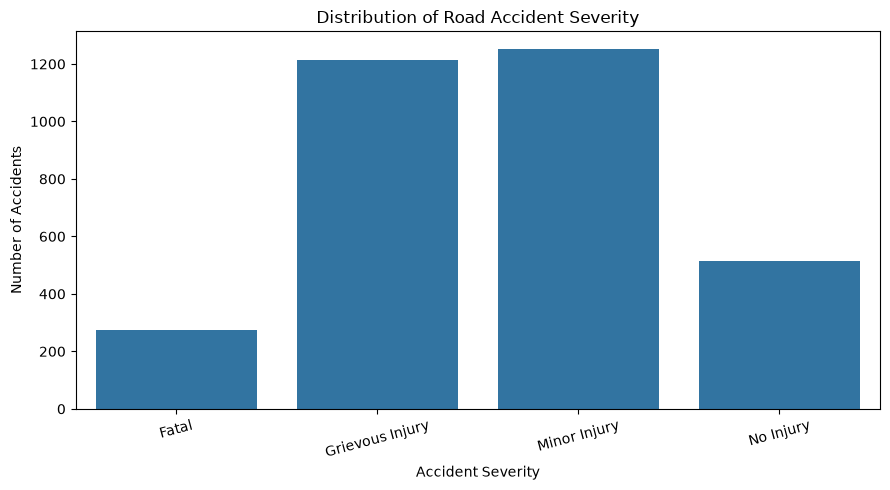

In [50]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x=df['Accident_Severity_C'].map(severity_labels),
    order=['Fatal', 'Grievous Injury', 'Minor Injury', 'No Injury']
)

plt.title('Distribution of Road Accident Severity')
plt.xlabel('Accident Severity')
plt.ylabel('Number of Accidents')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [51]:
# Count accidents by time period and severity
period_severity = pd.crosstab(
    df['Accident_Period'],
    df['Accident_Severity_C']
)

period_severity.columns = [
    'Fatal',
    'Grievous Injury',
    'Minor Injury',
    'No Injury'
]

print("Accident counts by time period:")
print(period_severity)

# Calculate percentages within each time period
period_severity_percentage = pd.crosstab(
    df['Accident_Period'],
    df['Accident_Severity_C'],
    normalize='index'
) * 100

period_severity_percentage.columns = [
    'Fatal',
    'Grievous Injury',
    'Minor Injury',
    'No Injury'
]

print("\nSeverity percentages within each time period:")
print(period_severity_percentage.round(2))

Accident counts by time period:
                 Fatal  Grievous Injury  Minor Injury  No Injury
Accident_Period                                                 
Afternoon           61              231           269         99
Evening             55              282           242         62
Morning             74              324           384        180
Night               84              378           356        172

Severity percentages within each time period:
                 Fatal  Grievous Injury  Minor Injury  No Injury
Accident_Period                                                 
Afternoon         9.24            35.00         40.76      15.00
Evening           8.58            43.99         37.75       9.67
Morning           7.69            33.68         39.92      18.71
Night             8.48            38.18         35.96      17.37


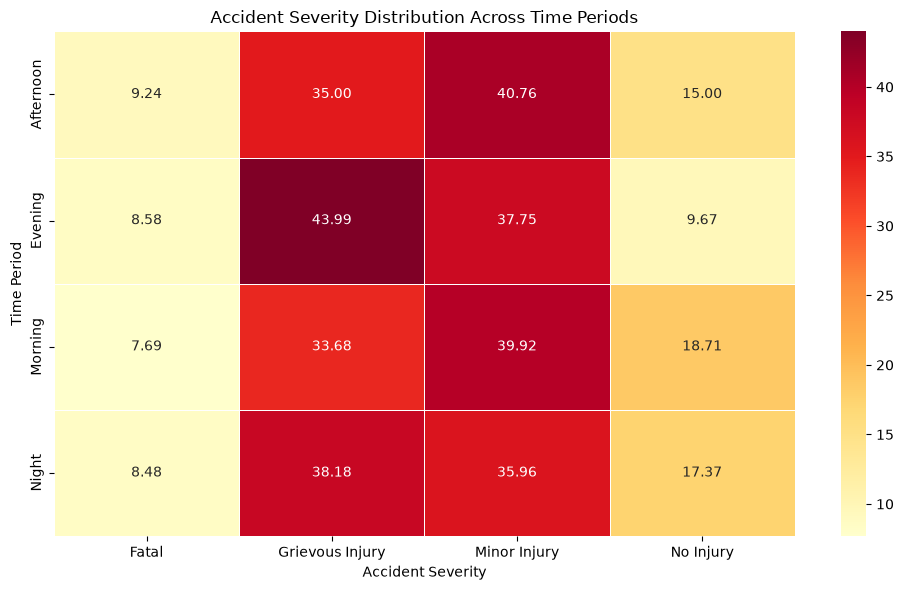

In [52]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    period_severity_percentage,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    linewidths=0.5
)

plt.title('Accident Severity Distribution Across Time Periods')
plt.xlabel('Accident Severity')
plt.ylabel('Time Period')
plt.tight_layout()
plt.show()

In [53]:
# Accident counts by location and severity
location_severity = pd.crosstab(
    df['Accident_Location_A'],
    df['Accident_Severity_C']
)

location_severity.index = ['Urban', 'Rural']
location_severity.columns = [
    'Fatal',
    'Grievous Injury',
    'Minor Injury',
    'No Injury'
]

print("Accident counts by location:")
print(location_severity)

# Percentage distribution within each location
location_severity_percentage = pd.crosstab(
    df['Accident_Location_A'],
    df['Accident_Severity_C'],
    normalize='index'
) * 100

location_severity_percentage.index = ['Urban', 'Rural']
location_severity_percentage.columns = [
    'Fatal',
    'Grievous Injury',
    'Minor Injury',
    'No Injury'
]

print("\nSeverity percentages by location:")
print(location_severity_percentage.round(2))

Accident counts by location:
       Fatal  Grievous Injury  Minor Injury  No Injury
Urban     46              226           205         34
Rural    228              989          1046        479

Severity percentages by location:
       Fatal  Grievous Injury  Minor Injury  No Injury
Urban   9.00            44.23         40.12       6.65
Rural   8.32            36.07         38.15      17.47


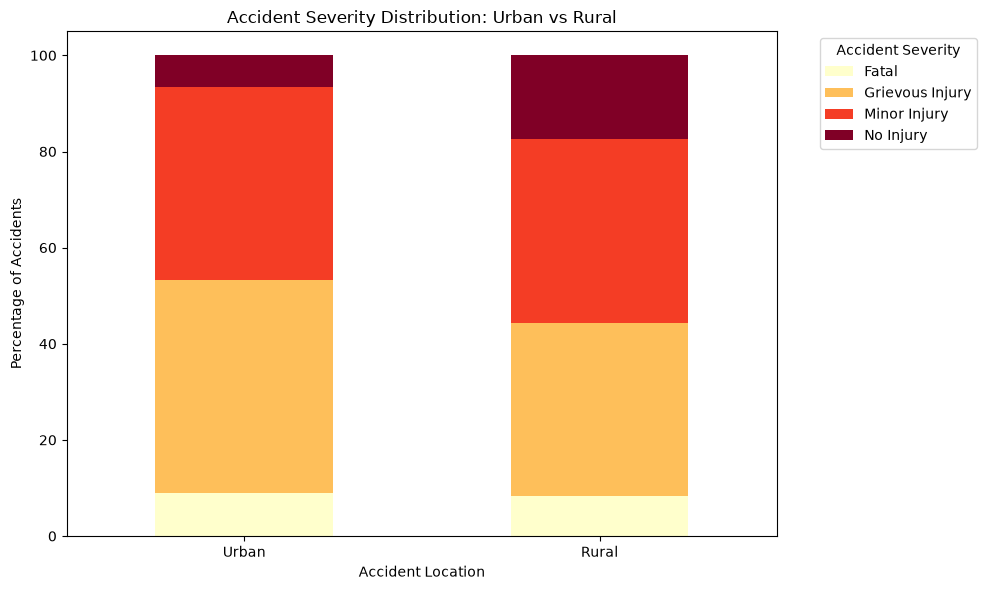

In [54]:
location_severity_percentage.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    colormap='YlOrRd'
)

plt.title('Accident Severity Distribution: Urban vs Rural')
plt.xlabel('Accident Location')
plt.ylabel('Percentage of Accidents')
plt.xticks(rotation=0)
plt.legend(title='Accident Severity', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

In [55]:
# Count accidents by road condition and severity
road_severity = pd.crosstab(
    df['Road_Condition_F'],
    df['Accident_Severity_C']
)

print("Accident counts by road condition:")
print(road_severity)

# Calculate percentages within each road condition
road_severity_percentage = pd.crosstab(
    df['Road_Condition_F'],
    df['Accident_Severity_C'],
    normalize='index'
) * 100

print("\nSeverity percentages by road condition:")
print(road_severity_percentage.round(2))

Accident counts by road condition:
Accident_Severity_C    1     2    3    4
Road_Condition_F                        
1.0                  225  1046  965  358
2.0                   17    83  110   75
3.0                    5    15   39   13
4.0                   25    59  114   47
5.0                    2     3    8    5
6.0                    0     2    6    7
7.0                    0     2    1    3
8.0                    0     5    7    5

Severity percentages by road condition:
Accident_Severity_C      1      2      3      4
Road_Condition_F                               
1.0                   8.67  40.32  37.20  13.80
2.0                   5.96  29.12  38.60  26.32
3.0                   6.94  20.83  54.17  18.06
4.0                  10.20  24.08  46.53  19.18
5.0                  11.11  16.67  44.44  27.78
6.0                   0.00  13.33  40.00  46.67
7.0                   0.00  33.33  16.67  50.00
8.0                   0.00  29.41  41.18  29.41


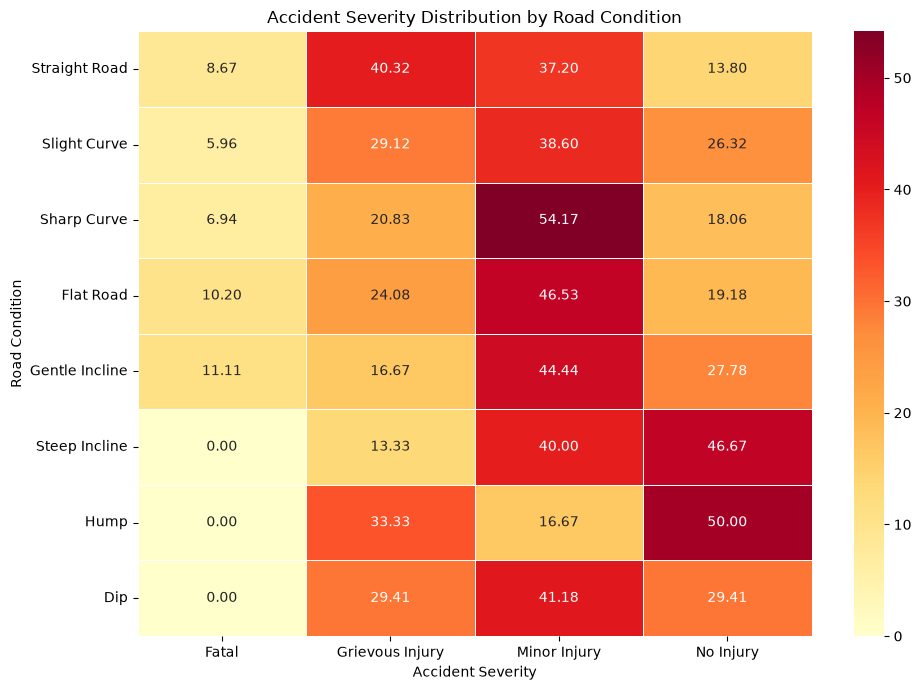

In [56]:
road_labels = {
    1: 'Straight Road',
    2: 'Slight Curve',
    3: 'Sharp Curve',
    4: 'Flat Road',
    5: 'Gentle Incline',
    6: 'Steep Incline',
    7: 'Hump',
    8: 'Dip'
}

road_plot_data = road_severity_percentage.copy()

road_plot_data.index = [
    road_labels[int(code)]
    for code in road_plot_data.index
]

road_plot_data.columns = [
    'Fatal',
    'Grievous Injury',
    'Minor Injury',
    'No Injury'
]

plt.figure(figsize=(10, 7))

sns.heatmap(
    road_plot_data,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    linewidths=0.5
)

plt.title('Accident Severity Distribution by Road Condition')
plt.xlabel('Accident Severity')
plt.ylabel('Road Condition')
plt.tight_layout()
plt.show()

In [57]:
weather_labels = {
    1: 'Fine',
    2: 'Mist/Fog',
    3: 'Cloud',
    4: 'Light Rain',
    5: 'Heavy Rain',
    6: 'Hail/Sleet',
    7: 'Snow',
    8: 'Strong Wind',
    9: 'Dust Storm',
    10: 'Very Hot',
    11: 'Very Cold',
    12: 'Other'
}

# Accident counts by weather and severity
weather_severity = pd.crosstab(
    df['Weather_Conditions_H'],
    df['Accident_Severity_C']
)

print("Accident counts by weather:")
print(weather_severity)

# Severity percentages within each weather category
weather_severity_percentage = pd.crosstab(
    df['Weather_Conditions_H'],
    df['Accident_Severity_C'],
    normalize='index'
) * 100

print("\nSeverity percentages by weather:")
print(weather_severity_percentage.round(2))

print("\nMissing weather records:", df['Weather_Conditions_H'].isna().sum())

Accident counts by weather:
Accident_Severity_C     1    2    3    4
Weather_Conditions_H                    
1.0                   163  759  727  243
2.0                    52  214  209  118
3.0                    15   75   88   39
4.0                     8   43   27   12
5.0                     1    9    0    1
6.0                     0    0    1    0
7.0                     0    0    4    3
8.0                     1    8   29   10
9.0                     8   17   40   30
10.0                   19   63  101   37
11.0                    4   12   11    6
12.0                    1    4    8   11

Severity percentages by weather:
Accident_Severity_C       1      2       3      4
Weather_Conditions_H                             
1.0                    8.62  40.12   38.42  12.84
2.0                    8.77  36.09   35.24  19.90
3.0                    6.91  34.56   40.55  17.97
4.0                    8.89  47.78   30.00  13.33
5.0                    9.09  81.82    0.00   9.09
6.0           

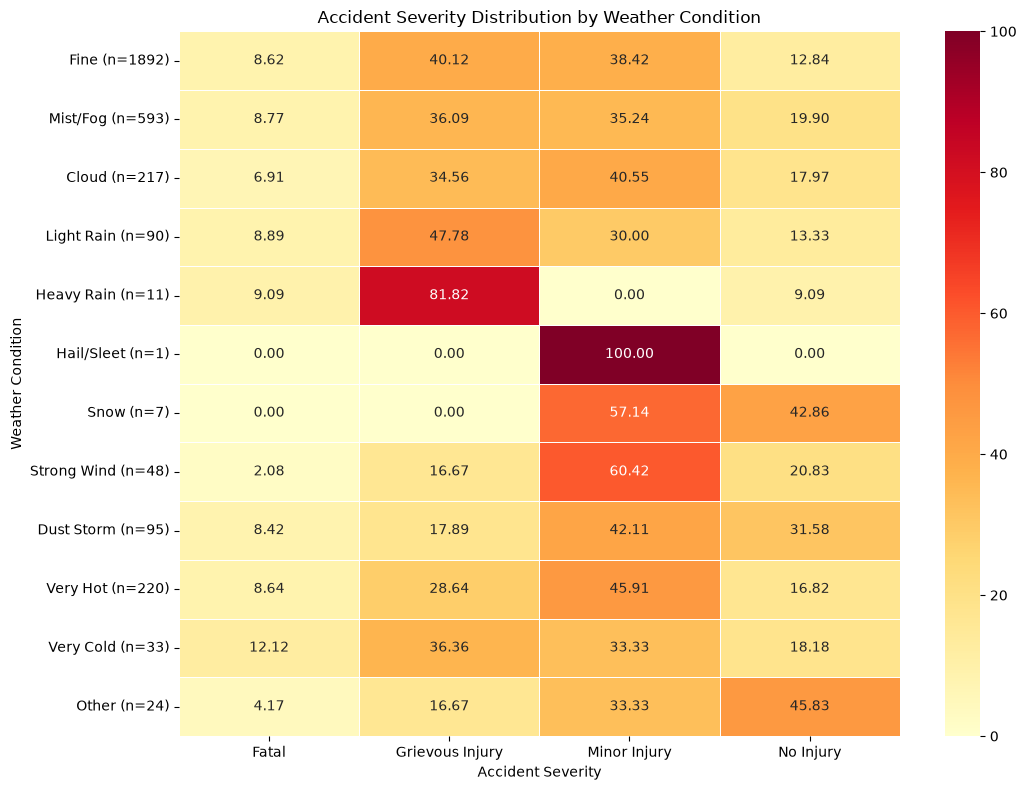

In [58]:
weather_plot_data = weather_severity_percentage.copy()

# Add category names and sample sizes
weather_plot_data.index = [
    f"{weather_labels[int(code)]} (n={int(weather_severity.loc[code].sum())})"
    for code in weather_plot_data.index
]

weather_plot_data.columns = [
    'Fatal',
    'Grievous Injury',
    'Minor Injury',
    'No Injury'
]

plt.figure(figsize=(11, 8))

sns.heatmap(
    weather_plot_data,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    linewidths=0.5
)

plt.title('Accident Severity Distribution by Weather Condition')
plt.xlabel('Accident Severity')
plt.ylabel('Weather Condition')
plt.tight_layout()
plt.show()

In [59]:
vehicle_labels = {
    1: 'Car/Jeep/Van',
    2: 'SUV',
    3: 'Bus',
    4: 'Mini Bus',
    5: 'Truck',
    6: 'Two Wheeler',
    7: 'Three Wheeler',
    8: 'Cycle',
    9: 'Pedestrian',
    10: 'Tractor',
    11: 'Unknown',
    12: 'Animal',
    14: 'LCV',
    15: 'MAV'
}

# Count accidents by vehicle type and severity
vehicle_severity = pd.crosstab(
    df['Vehicle_Type_Involved_J_V1'],
    df['Accident_Severity_C']
)

print("Accident counts by vehicle type:")
print(vehicle_severity)

# Calculate percentages within each vehicle category
vehicle_severity_percentage = pd.crosstab(
    df['Vehicle_Type_Involved_J_V1'],
    df['Accident_Severity_C'],
    normalize='index'
) * 100

print("\nSeverity percentages by vehicle type:")
print(vehicle_severity_percentage.round(2))

Accident counts by vehicle type:
Accident_Severity_C          1    2    3    4
Vehicle_Type_Involved_J_V1                   
1                           38  236  255  151
2                            1    6    8    5
3                            8   33   34   16
4                            1    3    5    1
5                           75  275  411  196
6                           72  391  352   68
7                            6   18   12    3
8                            2   20    8    0
9                           19   81   50    1
10                           4    7   11    8
11                          38  113   89   44
12                           2    5    0    0
14                           7   15   13   14
15                           1   12    3    6

Severity percentages by vehicle type:
Accident_Severity_C             1      2      3      4
Vehicle_Type_Involved_J_V1                            
1                            5.59  34.71  37.50  22.21
2                          

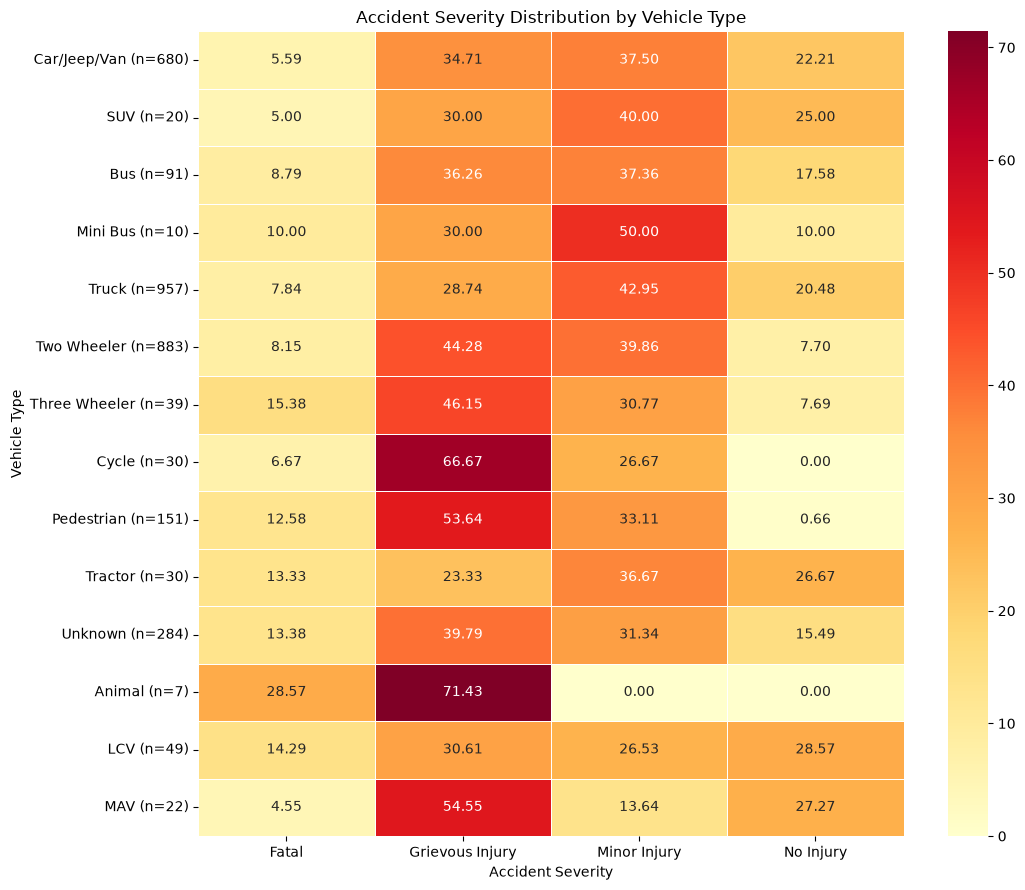

In [60]:
vehicle_plot_data = vehicle_severity_percentage.copy()

vehicle_plot_data.index = [
    f"{vehicle_labels[int(code)]} (n={int(vehicle_severity.loc[code].sum())})"
    for code in vehicle_plot_data.index
]

vehicle_plot_data.columns = [
    'Fatal',
    'Grievous Injury',
    'Minor Injury',
    'No Injury'
]

plt.figure(figsize=(11, 9))

sns.heatmap(
    vehicle_plot_data,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    linewidths=0.5
)

plt.title('Accident Severity Distribution by Vehicle Type')
plt.xlabel('Accident Severity')
plt.ylabel('Vehicle Type')
plt.tight_layout()
plt.show()

In [61]:
# Accident counts by number of vehicles and severity
vehicle_count_severity = pd.crosstab(
    df['Number_of_Vehicles'],
    df['Accident_Severity_C']
)

vehicle_count_severity.columns = [
    'Fatal',
    'Grievous Injury',
    'Minor Injury',
    'No Injury'
]

print("Accident counts by number of vehicles:")
print(vehicle_count_severity)

# Calculate percentages within each vehicle-count category
vehicle_count_percentage = pd.crosstab(
    df['Number_of_Vehicles'],
    df['Accident_Severity_C'],
    normalize='index'
) * 100

vehicle_count_percentage.columns = [
    'Fatal',
    'Grievous Injury',
    'Minor Injury',
    'No Injury'
]

print("\nSeverity percentages:")
print(vehicle_count_percentage.round(2))

Accident counts by number of vehicles:
                    Fatal  Grievous Injury  Minor Injury  No Injury
Number_of_Vehicles                                                 
1                     188              938           957        414
2                      86              276           290         99
3                       0                1             3          0
4                       0                0             1          0

Severity percentages:
                    Fatal  Grievous Injury  Minor Injury  No Injury
Number_of_Vehicles                                                 
1                    7.53            37.57         38.33      16.58
2                   11.45            36.75         38.62      13.18
3                    0.00            25.00         75.00       0.00
4                    0.00             0.00        100.00       0.00


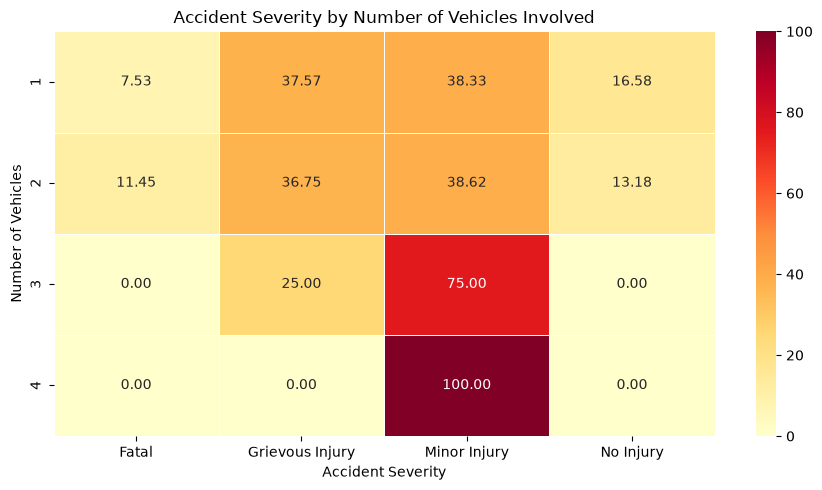

In [62]:
plt.figure(figsize=(9, 5))

sns.heatmap(
    vehicle_count_percentage,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    linewidths=0.5
)

plt.title('Accident Severity by Number of Vehicles Involved')
plt.xlabel('Accident Severity')
plt.ylabel('Number of Vehicles')
plt.tight_layout()
plt.show()


In [63]:
# Accident counts by nature and severity
nature_severity = pd.crosstab(
    df['Nature_of_Accident_B1'],
    df['Accident_Severity_C']
)

nature_severity.columns = [
    'Fatal',
    'Grievous Injury',
    'Minor Injury',
    'No Injury'
]

print("Accident counts by nature:")
print(nature_severity)

# Severity percentages within each accident nature
nature_severity_percentage = pd.crosstab(
    df['Nature_of_Accident_B1'],
    df['Accident_Severity_C'],
    normalize='index'
) * 100

nature_severity_percentage.columns = [
    'Fatal',
    'Grievous Injury',
    'Minor Injury',
    'No Injury'
]

print("\nSeverity percentages by nature:")
print(nature_severity_percentage.round(2))

print(
    "\nMissing nature records:",
    df['Nature_of_Accident_B1'].isna().sum()
)

Accident counts by nature:
                       Fatal  Grievous Injury  Minor Injury  No Injury
Nature_of_Accident_B1                                                 
1                         31              326           341        146
2                         67              121           106         55
3                         83              185           203        108
4                          8               44            44         29
5                          5               17            26         11
6                         19              196           245         74
7                          3                1             0          6
7a                         1               33             7          0
7b                        29              120            55          1
7c                         5               20             6          5
7d                         8              100           159         58
7e                         2                4     

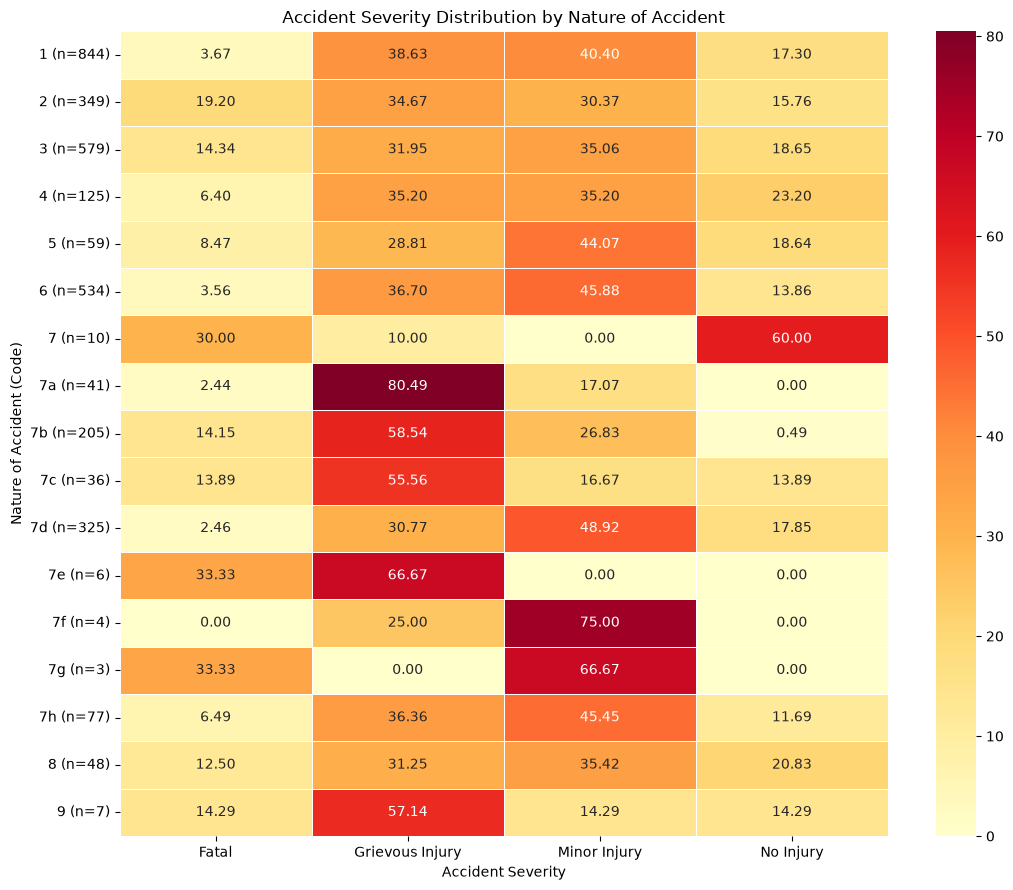

In [64]:
nature_plot_data = nature_severity_percentage.copy()

nature_plot_data.index = [
    f"{code} (n={int(nature_severity.loc[code].sum())})"
    for code in nature_plot_data.index
]

plt.figure(figsize=(11, 9))

sns.heatmap(
    nature_plot_data,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    linewidths=0.5
)

plt.title('Accident Severity Distribution by Nature of Accident')
plt.xlabel('Accident Severity')
plt.ylabel('Nature of Accident (Code)')
plt.tight_layout()
plt.show()

In [65]:
# Accident counts by cause and severity
cause_severity = pd.crosstab(
    df['Causes_D1'],
    df['Accident_Severity_C']
)

cause_severity.columns = [
    'Fatal',
    'Grievous Injury',
    'Minor Injury',
    'No Injury'
]

print("Accident counts by cause:")
print(cause_severity)

# Severity percentages within each cause
cause_severity_percentage = pd.crosstab(
    df['Causes_D1'],
    df['Accident_Severity_C'],
    normalize='index'
) * 100

cause_severity_percentage.columns = [
    'Fatal',
    'Grievous Injury',
    'Minor Injury',
    'No Injury'
]

print("\nSeverity percentages by cause:")
print(cause_severity_percentage.round(2))

print("\nMissing cause records:", df['Causes_D1'].isna().sum())

Accident counts by cause:
           Fatal  Grievous Injury  Minor Injury  No Injury
Causes_D1                                                 
1             19               81            96         18
2            150              563           524        196
3             72              480           542        227
4             30               77            70         64
4a             2                2             5          2
4d             0                0             1          0
4f             0                0             1          0
5              1                8             3          3
5a             0                2             8          2
6              0                0             1          0
8              0                1             0          1

Severity percentages by cause:
           Fatal  Grievous Injury  Minor Injury  No Injury
Causes_D1                                                 
1           8.88            37.85         44.86       8.4

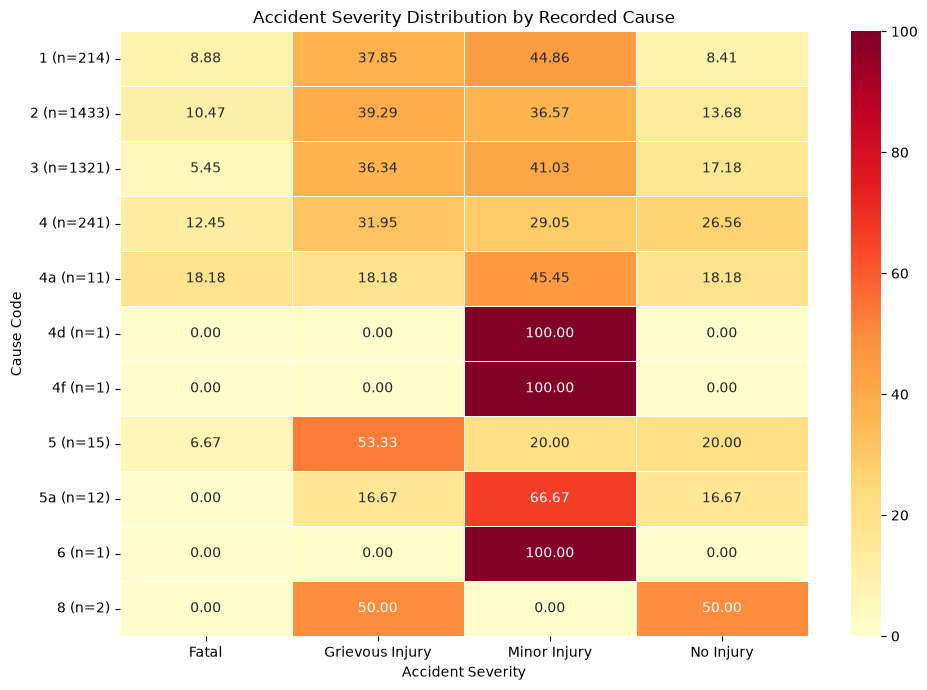

In [66]:
cause_plot_data = cause_severity_percentage.copy()

cause_plot_data.index = [
    f"{code} (n={int(cause_severity.loc[code].sum())})"
    for code in cause_plot_data.index
]

plt.figure(figsize=(10, 7))

sns.heatmap(
    cause_plot_data,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    linewidths=0.5
)

plt.title('Accident Severity Distribution by Recorded Cause')
plt.xlabel('Accident Severity')
plt.ylabel('Cause Code')
plt.tight_layout()
plt.show()

In [67]:
day_labels = {
    1: 'Monday',
    2: 'Tuesday',
    3: 'Wednesday',
    4: 'Thursday',
    5: 'Friday',
    6: 'Saturday',
    7: 'Sunday'
}

day_severity = pd.crosstab(
    df['Day_of_Week'],
    df['Accident_Severity_C']
)

day_severity_percentage = pd.crosstab(
    df['Day_of_Week'],
    df['Accident_Severity_C'],
    normalize='index'
) * 100

day_severity.index = [
    day_labels[int(day)] for day in day_severity.index
]

day_severity_percentage.index = [
    day_labels[int(day)] for day in day_severity_percentage.index
]

day_severity.columns = [
    'Fatal', 'Grievous Injury', 'Minor Injury', 'No Injury'
]

day_severity_percentage.columns = [
    'Fatal', 'Grievous Injury', 'Minor Injury', 'No Injury'
]

print("Accident counts by day:")
print(day_severity)

print("\nSeverity percentages by day:")
print(day_severity_percentage.round(2))

Accident counts by day:
           Fatal  Grievous Injury  Minor Injury  No Injury
Monday        36              151           171         78
Tuesday       34              159           165         69
Wednesday     46              162           155         76
Thursday      42              180           197         73
Friday        38              162           201         71
Saturday      40              205           196         77
Sunday        38              196           166         69

Severity percentages by day:
           Fatal  Grievous Injury  Minor Injury  No Injury
Monday      8.26            34.63         39.22      17.89
Tuesday     7.96            37.24         38.64      16.16
Wednesday  10.48            36.90         35.31      17.31
Thursday    8.54            36.59         40.04      14.84
Friday      8.05            34.32         42.58      15.04
Saturday    7.72            39.58         37.84      14.86
Sunday      8.10            41.79         35.39      14.71


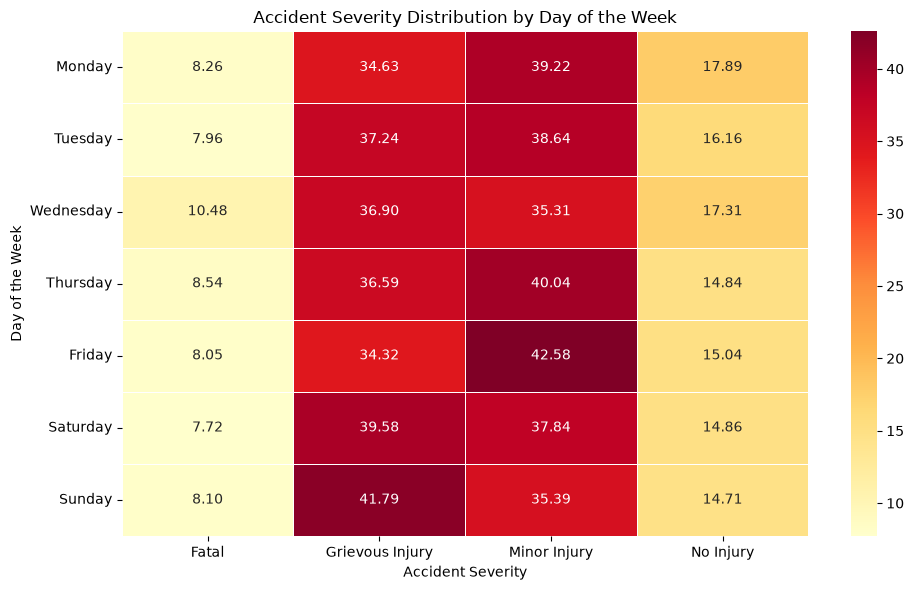

In [68]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    day_severity_percentage,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    linewidths=0.5
)

plt.title('Accident Severity Distribution by Day of the Week')
plt.xlabel('Accident Severity')
plt.ylabel('Day of the Week')
plt.tight_layout()
plt.show()

In [69]:
road_feature_labels = {
    1: 'Single Lane',
    2: 'Two Lanes',
    3: 'Three or More Lanes (No Divider)',
    4: 'Four or More Lanes (With Divider)',
    5: 'Undocumented Code 5',
    9: 'Undocumented Code 9'
}

# Accident counts by road feature
road_feature_severity = pd.crosstab(
    df['Road_Feature_E'],
    df['Accident_Severity_C']
)

road_feature_percentage = pd.crosstab(
    df['Road_Feature_E'],
    df['Accident_Severity_C'],
    normalize='index'
) * 100

road_feature_severity.columns = [
    'Fatal', 'Grievous Injury', 'Minor Injury', 'No Injury'
]

road_feature_percentage.columns = [
    'Fatal', 'Grievous Injury', 'Minor Injury', 'No Injury'
]

road_feature_severity.index = [
    road_feature_labels.get(int(code), str(code))
    for code in road_feature_severity.index
]

road_feature_percentage.index = [
    road_feature_labels.get(int(code), str(code))
    for code in road_feature_percentage.index
]

print("Accident counts by road feature:")
print(road_feature_severity)

print("\nSeverity percentages by road feature:")
print(road_feature_percentage.round(2))

Accident counts by road feature:
                                   Fatal  Grievous Injury  Minor Injury  \
Single Lane                            3               11            11   
Two Lanes                             54              172           227   
Three or More Lanes (No Divider)       0                1             1   
Four or More Lanes (With Divider)    217             1031          1011   
Undocumented Code 5                    0                0             0   
Undocumented Code 9                    0                0             1   

                                   No Injury  
Single Lane                                4  
Two Lanes                                142  
Three or More Lanes (No Divider)           2  
Four or More Lanes (With Divider)        364  
Undocumented Code 5                        1  
Undocumented Code 9                        0  

Severity percentages by road feature:
                                   Fatal  Grievous Injury  Minor Injury  

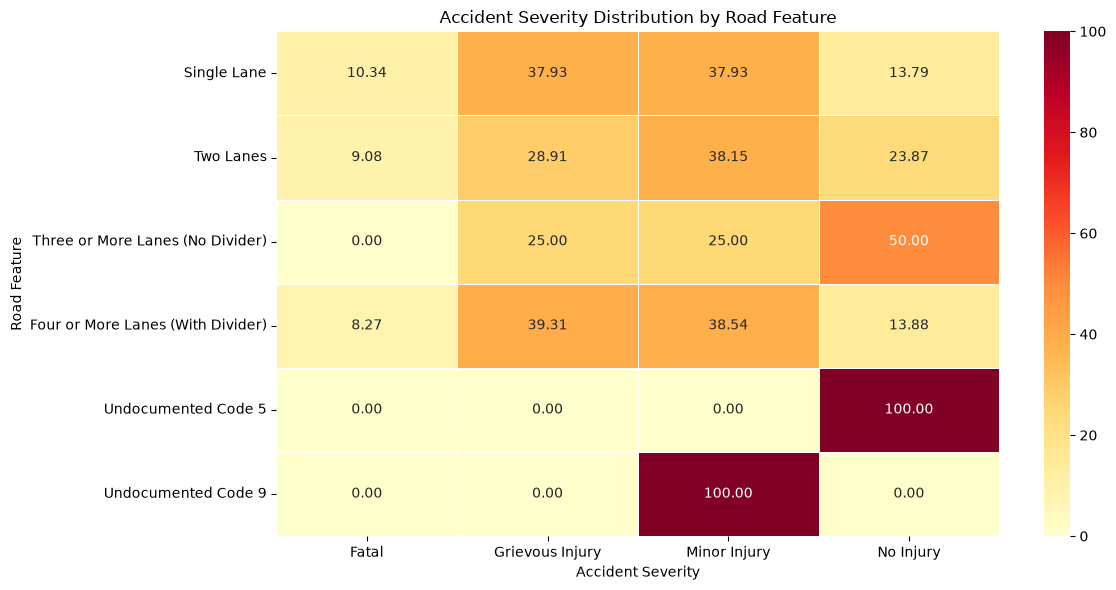

In [70]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    road_feature_percentage,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    linewidths=0.5
)

plt.title('Accident Severity Distribution by Road Feature')
plt.xlabel('Accident Severity')
plt.ylabel('Road Feature')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [71]:
target_column = 'Accident_Severity_C'

selected_features = [
    'Day_of_Week',
    'Accident_Hour',
    'Accident_Year',
    'Accident_Month',
    'Accident_Location_A',
    'Accident_Location_A_Chainage_km_RoadSide',
    'Nature_of_Accident_B1',
    'Causes_D1',
    'Road_Feature_E',
    'Road_Condition_F',
    'Intersection_Type_G',
    'Weather_Conditions_H',
    'Vehicle_Type_Involved_J_V1',
    'Number_of_Vehicles'
]

print("Number of selected features:", len(selected_features))

print("\nSelected features:")
for feature in selected_features:
    print(feature)

print("\nMissing values in selected features:")
print(df[selected_features].isnull().sum())

Number of selected features: 14

Selected features:
Day_of_Week
Accident_Hour
Accident_Year
Accident_Month
Accident_Location_A
Accident_Location_A_Chainage_km_RoadSide
Nature_of_Accident_B1
Causes_D1
Road_Feature_E
Road_Condition_F
Intersection_Type_G
Weather_Conditions_H
Vehicle_Type_Involved_J_V1
Number_of_Vehicles

Missing values in selected features:
Day_of_Week                                    0
Accident_Hour                                  0
Accident_Year                                  0
Accident_Month                                 0
Accident_Location_A                            0
Accident_Location_A_Chainage_km_RoadSide       0
Nature_of_Accident_B1                          1
Causes_D1                                      1
Road_Feature_E                                 0
Road_Condition_F                               1
Intersection_Type_G                         1869
Weather_Conditions_H                          22
Vehicle_Type_Involved_J_V1                     0
Number

In [72]:
# Create separate copies for machine learning
X = df[selected_features].copy()

y = df[target_column].copy()

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts().sort_index())

print("\nTotal missing values in features:", X.isnull().sum().sum())

Feature dataset shape: (3253, 14)
Target dataset shape: (3253,)

Target distribution:
Accident_Severity_C
1     274
2    1215
3    1251
4     513
Name: count, dtype: int64

Total missing values in features: 1894


In [73]:
# Categorical features
categorical_features = [
    'Day_of_Week',
    'Accident_Location_A',
    'Accident_Location_A_Chainage_km_RoadSide',
    'Nature_of_Accident_B1',
    'Causes_D1',
    'Road_Feature_E',
    'Road_Condition_F',
    'Intersection_Type_G',
    'Weather_Conditions_H',
    'Vehicle_Type_Involved_J_V1',
    'Number_of_Vehicles'
]

# Numerical features
numerical_features = [
    'Accident_Hour',
    'Accident_Year',
    'Accident_Month'
]

print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))

print("\nCategorical feature data types:")
print(X[categorical_features].dtypes)

print("\nNumerical feature data types:")
print(X[numerical_features].dtypes)

Categorical features: 11
Numerical features: 3

Categorical feature data types:
Day_of_Week                                   int64
Accident_Location_A                           int64
Accident_Location_A_Chainage_km_RoadSide        str
Nature_of_Accident_B1                           str
Causes_D1                                       str
Road_Feature_E                                int64
Road_Condition_F                            float64
Intersection_Type_G                         float64
Weather_Conditions_H                        float64
Vehicle_Type_Involved_J_V1                    int64
Number_of_Vehicles                            int64
dtype: object

Numerical feature data types:
Accident_Hour     int32
Accident_Year     int32
Accident_Month    int32
dtype: object


In [74]:
# Exclude recorded cause from the initial prediction model
selected_features.remove('Causes_D1')

# Recreate feature dataset
X = df[selected_features].copy()

# Update categorical features
categorical_features.remove('Causes_D1')

# Numerical features remain unchanged
numerical_features = [
    'Accident_Hour',
    'Accident_Year',
    'Accident_Month'
]

print("Selected features:", len(selected_features))
print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))

print("\nFinal selected features:")
print(selected_features)

Selected features: 13
Categorical features: 10
Numerical features: 3

Final selected features:
['Day_of_Week', 'Accident_Hour', 'Accident_Year', 'Accident_Month', 'Accident_Location_A', 'Accident_Location_A_Chainage_km_RoadSide', 'Nature_of_Accident_B1', 'Road_Feature_E', 'Road_Condition_F', 'Intersection_Type_G', 'Weather_Conditions_H', 'Vehicle_Type_Involved_J_V1', 'Number_of_Vehicles']


In [75]:
# Convert categorical feature values to strings
# Keep missing values as NaN so we can impute them later

for col in categorical_features:
    X[col] = X[col].map(
        lambda value: str(value) if pd.notna(value) else np.nan
    )

# Check the resulting data types
print(X[categorical_features].dtypes)

# Check missing values in selected features
print("\nMissing values:")
print(X.isnull().sum())

print("\nTotal missing values:", X.isnull().sum().sum())

Day_of_Week                                 str
Accident_Location_A                         str
Accident_Location_A_Chainage_km_RoadSide    str
Nature_of_Accident_B1                       str
Road_Feature_E                              str
Road_Condition_F                            str
Intersection_Type_G                         str
Weather_Conditions_H                        str
Vehicle_Type_Involved_J_V1                  str
Number_of_Vehicles                          str
dtype: object

Missing values:
Day_of_Week                                    0
Accident_Hour                                  0
Accident_Year                                  0
Accident_Month                                 0
Accident_Location_A                            0
Accident_Location_A_Chainage_km_RoadSide       0
Nature_of_Accident_B1                          1
Road_Feature_E                                 0
Road_Condition_F                               1
Intersection_Type_G                         1869

In [76]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

Training data shape: (2602, 13)
Testing data shape: (651, 13)

Training target distribution:
Accident_Severity_C
1    0.084
2    0.374
3    0.385
4    0.158
Name: proportion, dtype: float64

Testing target distribution:
Accident_Severity_C
1    0.084
2    0.373
3    0.384
4    0.158
Name: proportion, dtype: float64


In [77]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Preprocessing for categorical features
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='Unknown')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Preprocessing for numerical features
numerical_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

# Combine both transformations
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', categorical_transformer, categorical_features),
        ('num', numerical_transformer, numerical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [78]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

# Create Decision Tree model pipeline
decision_tree_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        random_state=42,
        class_weight='balanced'
    ))
])

# Train the model
decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


Decision Tree Accuracy: 0.3641

Classification Report:
                 precision    recall  f1-score   support

          Fatal       0.11      0.15      0.13        55
Grievous Injury       0.43      0.44      0.43       243
   Minor Injury       0.41      0.37      0.39       250
      No Injury       0.28      0.29      0.28       103

       accuracy                           0.36       651
      macro avg       0.31      0.31      0.31       651
   weighted avg       0.37      0.36      0.37       651



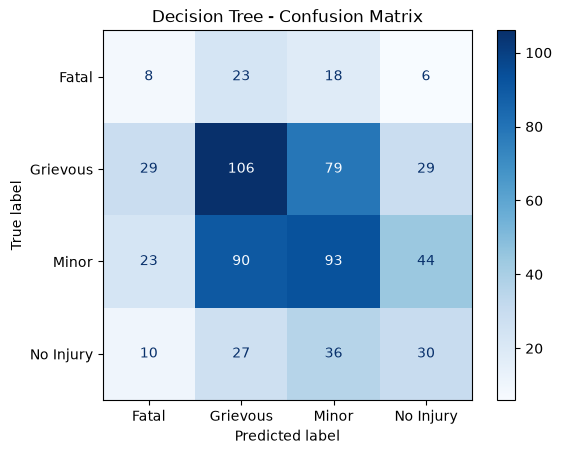

In [79]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Predict on testing data
y_pred_dt = decision_tree_model.predict(X_test)

# Calculate accuracy
accuracy_dt = accuracy_score(y_test, y_pred_dt)

print("Decision Tree Accuracy:", round(accuracy_dt, 4))

# Detailed classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_dt,
    labels=[1, 2, 3, 4],
    target_names=[
        'Fatal',
        'Grievous Injury',
        'Minor Injury',
        'No Injury'
    ],
    zero_division=0
))

# Confusion matrix
cm_dt = confusion_matrix(y_test, y_pred_dt, labels=[1, 2, 3, 4])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dt,
    display_labels=['Fatal', 'Grievous', 'Minor', 'No Injury']
)

disp.plot(cmap='Blues', values_format='d')
plt.title("Decision Tree - Confusion Matrix")
plt.show()

In [80]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create Random Forest model pipeline
random_forest_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    ))
])

# Train the model
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


Random Forest Accuracy: 0.4378

Classification Report:
                 precision    recall  f1-score   support

          Fatal       0.19      0.18      0.18        55
Grievous Injury       0.51      0.50      0.50       243
   Minor Injury       0.49      0.49      0.49       250
      No Injury       0.29      0.30      0.29       103

       accuracy                           0.44       651
      macro avg       0.37      0.37      0.37       651
   weighted avg       0.44      0.44      0.44       651



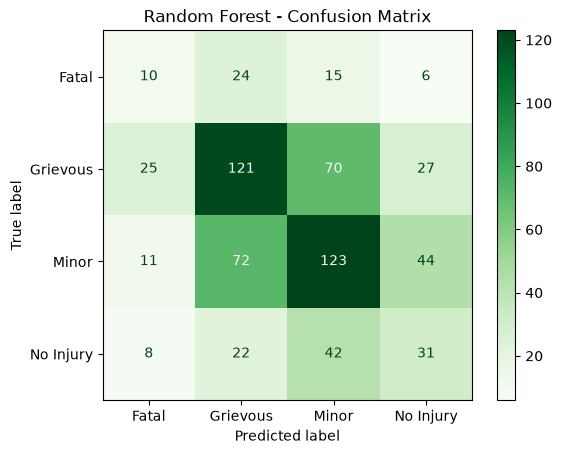

In [81]:
# Predict on testing data
y_pred_rf = random_forest_model.predict(X_test)

# Calculate accuracy
accuracy_rf = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", round(accuracy_rf, 4))

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    labels=[1, 2, 3, 4],
    target_names=[
        'Fatal',
        'Grievous Injury',
        'Minor Injury',
        'No Injury'
    ],
    zero_division=0
))

# Confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=[1, 2, 3, 4])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=['Fatal', 'Grievous', 'Minor', 'No Injury']
)

disp.plot(cmap='Greens', values_format='d')
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [82]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline

# Create Gradient Boosting model pipeline
gradient_boosting_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

# Train the model
gradient_boosting_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


Gradient Boosting Accuracy: 0.4716

Classification Report:
                 precision    recall  f1-score   support

          Fatal       0.35      0.11      0.17        55
Grievous Injury       0.48      0.55      0.51       243
   Minor Injury       0.48      0.60      0.53       250
      No Injury       0.41      0.18      0.26       103

       accuracy                           0.47       651
      macro avg       0.43      0.36      0.37       651
   weighted avg       0.46      0.47      0.45       651



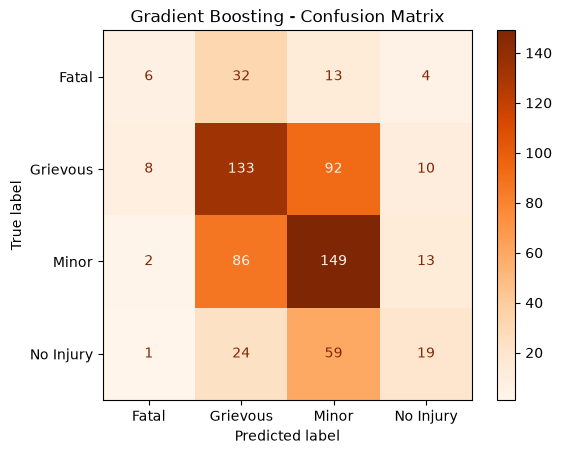

In [83]:
# Predict on testing data
y_pred_gb = gradient_boosting_model.predict(X_test)

# Calculate accuracy
accuracy_gb = accuracy_score(y_test, y_pred_gb)

print("Gradient Boosting Accuracy:", round(accuracy_gb, 4))

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_gb,
    labels=[1, 2, 3, 4],
    target_names=[
        'Fatal',
        'Grievous Injury',
        'Minor Injury',
        'No Injury'
    ],
    zero_division=0
))

# Confusion matrix
cm_gb = confusion_matrix(y_test, y_pred_gb, labels=[1, 2, 3, 4])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_gb,
    display_labels=['Fatal', 'Grievous', 'Minor', 'No Injury']
)

disp.plot(cmap='Oranges', values_format='d')
plt.title("Gradient Boosting - Confusion Matrix")
plt.show()

Model Comparison Table

In [84]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = {
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "Gradient Boosting": y_pred_gb
}

results = []

for name, predictions in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Precision": precision_score(
            y_test, predictions, average='macro', zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, predictions, average='macro', zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions, average='macro', zero_division=0
        ),
        "Fatal Recall": recall_score(
            y_test, predictions, labels=[1], average='macro', zero_division=0
        )
    })

comparison_df = pd.DataFrame(results)

print(comparison_df.round(4).to_string(index=False))

            Model  Accuracy  Macro Precision  Macro Recall  Macro F1  Fatal Recall
    Decision Tree    0.3641           0.3080        0.3112    0.3088        0.1455
    Random Forest    0.4378           0.3676        0.3682    0.3678        0.1818
Gradient Boosting    0.4716           0.4314        0.3592    0.3661        0.1091


In [85]:
# Create improved Random Forest model
rf_balanced_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight='balanced_subsample',
        min_samples_leaf=2,
        n_jobs=-1
    ))
])

# Train the model
rf_balanced_model.fit(X_train, y_train)

print("Improved Random Forest model trained successfully!")

Improved Random Forest model trained successfully!


In [86]:
# Predict using improved Random Forest
y_pred_rf_balanced = rf_balanced_model.predict(X_test)

# Print accuracy
print(
    "Improved Random Forest Accuracy:",
    round(accuracy_score(y_test, y_pred_rf_balanced), 4)
)

# Classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf_balanced,
    labels=[1, 2, 3, 4],
    target_names=[
        'Fatal',
        'Grievous Injury',
        'Minor Injury',
        'No Injury'
    ],
    zero_division=0
))

Improved Random Forest Accuracy: 0.4409

Classification Report:
                 precision    recall  f1-score   support

          Fatal       0.27      0.24      0.25        55
Grievous Injury       0.51      0.50      0.51       243
   Minor Injury       0.47      0.49      0.48       250
      No Injury       0.28      0.29      0.29       103

       accuracy                           0.44       651
      macro avg       0.38      0.38      0.38       651
   weighted avg       0.44      0.44      0.44       651



In [87]:
# Compare all four trained models

models = {
    "Decision Tree": y_pred_dt,
    "Random Forest": y_pred_rf,
    "Gradient Boosting": y_pred_gb,
    "Improved Random Forest": y_pred_rf_balanced
}

results = []

for name, predictions in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro Precision": precision_score(
            y_test, predictions, average='macro', zero_division=0
        ),
        "Macro Recall": recall_score(
            y_test, predictions, average='macro', zero_division=0
        ),
        "Macro F1": f1_score(
            y_test, predictions, average='macro', zero_division=0
        ),
        "Fatal Recall": recall_score(
            y_test, predictions, labels=[1],
            average='macro', zero_division=0
        )
    })

comparison_df = pd.DataFrame(results)

print(comparison_df.round(4).to_string(index=False))

                 Model  Accuracy  Macro Precision  Macro Recall  Macro F1  Fatal Recall
         Decision Tree    0.3641           0.3080        0.3112    0.3088        0.1455
         Random Forest    0.4378           0.3676        0.3682    0.3678        0.1818
     Gradient Boosting    0.4716           0.4314        0.3592    0.3661        0.1091
Improved Random Forest    0.4409           0.3845        0.3794    0.3815        0.2364


In [88]:
from sklearn.inspection import permutation_importance

# Calculate feature importance
importance = permutation_importance(
    rf_balanced_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='f1_macro',
    n_jobs=-1
)

# Create importance dataframe
feature_importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': importance.importances_mean,
    'Std': importance.importances_std
})

# Sort by importance
feature_importance_df = feature_importance_df.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance_df.to_string(index=False))

                                 Feature  Importance      Std
                   Nature_of_Accident_B1    0.049781 0.016850
                     Intersection_Type_G    0.032865 0.010749
              Vehicle_Type_Involved_J_V1    0.019431 0.015332
                          Road_Feature_E    0.012038 0.006036
                           Accident_Hour    0.008109 0.012008
                      Number_of_Vehicles    0.000981 0.007145
Accident_Location_A_Chainage_km_RoadSide    0.000892 0.010172
                        Road_Condition_F   -0.000827 0.005176
                           Accident_Year   -0.003317 0.007190
                          Accident_Month   -0.011379 0.007724
                     Accident_Location_A   -0.011967 0.005305
                    Weather_Conditions_H   -0.015231 0.006482
                             Day_of_Week   -0.023323 0.007431


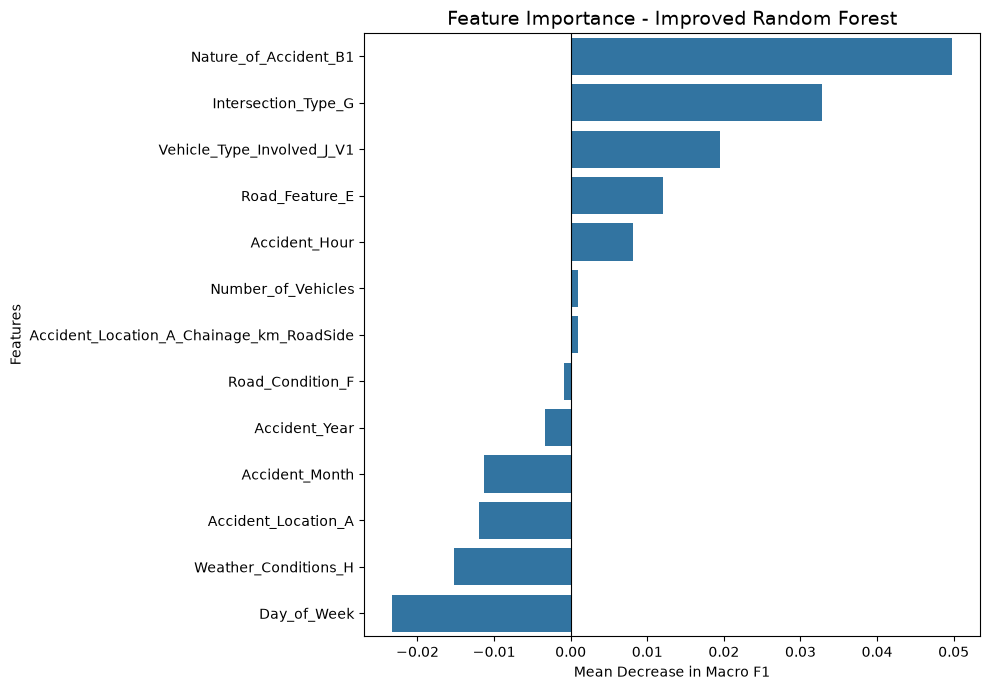

In [89]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance_df,
    x='Importance',
    y='Feature'
)

plt.title(
    'Feature Importance - Improved Random Forest',
    fontsize=14
)
plt.xlabel('Mean Decrease in Macro F1')
plt.ylabel('Features')
plt.axvline(x=0, color='black', linewidth=0.8)

plt.tight_layout()
plt.show()

In [90]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score

# Define 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluation metrics
scoring = {
    'accuracy': 'accuracy',
    'macro_f1': 'f1_macro',
    'macro_recall': 'recall_macro',
    'fatal_recall': make_scorer(
        recall_score,
        labels=[1],
        average='macro',
        zero_division=0
    )
}

# Perform cross-validation on training data
cv_results = cross_validate(
    rf_balanced_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

# Display average scores
print("5-Fold Cross-Validation Results")

for metric in scoring:
    scores = cv_results[f'test_{metric}']
    print(
        f"{metric}: {scores.mean():.4f} "
        f"(± {scores.std():.4f})"
    )

5-Fold Cross-Validation Results
accuracy: 0.4458 (± 0.0099)
macro_f1: 0.3827 (± 0.0115)
macro_recall: 0.3830 (± 0.0136)
fatal_recall: 0.2010 (± 0.0393)


In [91]:
# Create Random Forest with higher weight for Fatal accidents

rf_fatal_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight={
            1: 4,
            2: 1,
            3: 1,
            4: 1
        },
        min_samples_leaf=2,
        n_jobs=-1
    ))
])

# Train the model
rf_fatal_model.fit(X_train, y_train)

print("Fatal-focused Random Forest trained successfully!")

Fatal-focused Random Forest trained successfully!


In [92]:
# Make predictions using the Fatal-focused Random Forest
y_pred_rf_fatal = rf_fatal_model.predict(X_test)

# Evaluate model performance
print("Fatal-focused Random Forest Results")
print("-----------------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_rf_fatal))
print("Macro Precision:", precision_score(y_test, y_pred_rf_fatal, average='macro'))
print("Macro Recall:", recall_score(y_test, y_pred_rf_fatal, average='macro'))
print("Macro F1:", f1_score(y_test, y_pred_rf_fatal, average='macro'))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf_fatal,
    target_names=[
        'Fatal',
        'Grievous Injury',
        'Minor Injury',
        'No Injury'
    ]
))

Fatal-focused Random Forest Results
-----------------------------------
Accuracy: 0.46390168970814133
Macro Precision: 0.4039976231456438
Macro Recall: 0.38435312855269704
Macro F1: 0.3649231868729834

Classification Report:
                 precision    recall  f1-score   support

          Fatal       0.23      0.35      0.28        55
Grievous Injury       0.51      0.51      0.51       243
   Minor Injury       0.50      0.60      0.55       250
      No Injury       0.38      0.08      0.13       103

       accuracy                           0.46       651
      macro avg       0.40      0.38      0.36       651
   weighted avg       0.46      0.46      0.44       651



In [93]:
model_comparison = pd.DataFrame({
    'Model': [
        'Decision Tree',
        'Random Forest',
        'Gradient Boosting',
        'Improved Random Forest',
        'Fatal-focused Random Forest'
    ],
    'Accuracy': [
        0.3641, 0.4378, 0.4716, 0.4409, 0.4639
    ],
    'Macro Precision': [
        0.3080, 0.3676, 0.4314, 0.3845, 0.4040
    ],
    'Macro Recall': [
        0.3112, 0.3682, 0.3592, 0.3794, 0.3844
    ],
    'Macro F1': [
        0.3088, 0.3678, 0.3661, 0.3815, 0.3649
    ]
})

model_comparison.sort_values(
    by='Macro F1',
    ascending=False
).reset_index(drop=True)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Improved Random Forest,0.4409,0.3845,0.3794,0.3815
1,Random Forest,0.4378,0.3676,0.3682,0.3678
2,Gradient Boosting,0.4716,0.4314,0.3592,0.3661
3,Fatal-focused Random Forest,0.4639,0.4040,0.3844,0.3649
4,Decision Tree,0.3641,0.3080,0.3112,0.3088


### Model Comparison and Selection

Five machine learning experiments were compared using Accuracy, Macro Precision, Macro Recall, and Macro F1.

The Improved Random Forest achieved the highest Macro F1 score of 0.3815, indicating the best overall balance across the four accident severity classes among the tested models.

Gradient Boosting achieved the highest accuracy of 47.16%, but its lower Macro F1 indicates less balanced classification performance.

Therefore, the Improved Random Forest is selected as the current leading model for further evaluation.

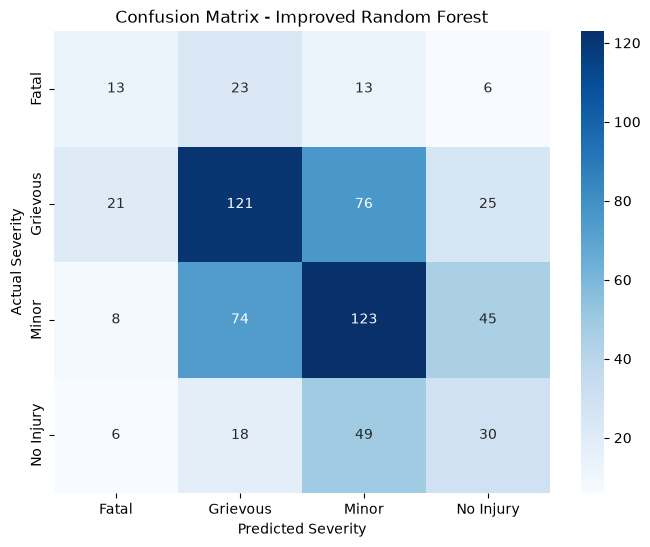

In [94]:
y_pred_best = rf_balanced_model.predict(X_test)

cm = confusion_matrix(y_test, y_pred_best)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Fatal', 'Grievous', 'Minor', 'No Injury'],
    yticklabels=['Fatal', 'Grievous', 'Minor', 'No Injury']
)

plt.xlabel('Predicted Severity')
plt.ylabel('Actual Severity')
plt.title('Confusion Matrix - Improved Random Forest')
plt.show()

### Confusion Matrix Analysis – Improved Random Forest

The confusion matrix provides a class-wise view of the model's predictions.

The model correctly classified 13 fatal, 121 grievous injury, 123 minor injury, and 30 no-injury accidents.

The results indicate that the model performs relatively better for grievous and minor injury categories. However, it struggles to distinguish between grievous and minor injuries, as well as correctly identify no-injury cases.

Overall, the confusion matrix highlights the challenges of classifying accident severity across all four categories.

### Final Model Selection – Improved Random Forest

Based on the model comparison and evaluation, the Improved Random Forest is selected as the leading model for this project.

It achieved a test Macro F1 score of 0.3815 and a 5-fold cross-validation Macro F1 score of 0.3827 (± 0.0115).

The similar scores indicate reasonably consistent performance. The model also provides a better balance across the four accident severity categories than the other tested models.

Although its accuracy is not the highest, its Macro F1 score makes it the most suitable candidate among the experiments conducted.

The model's performance is moderate, indicating scope for further improvement.

In [95]:
import joblib
from pathlib import Path

# Create the models folder if it doesn't exist
model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

# Save the trained model pipeline
model_path = model_dir / "improved_random_forest.pkl"

joblib.dump(rf_balanced_model, model_path)

print("Model saved successfully!")
print("Location:", model_path)

Model saved successfully!
Location: ..\models\improved_random_forest.pkl


In [96]:
# Create the outputs folder
output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Save model comparison results
results_path = output_dir / "model_comparison.csv"
model_comparison.to_csv(results_path, index=False)

print("Model comparison saved successfully!")
print("Location:", results_path)

Model comparison saved successfully!
Location: ..\outputs\model_comparison.csv


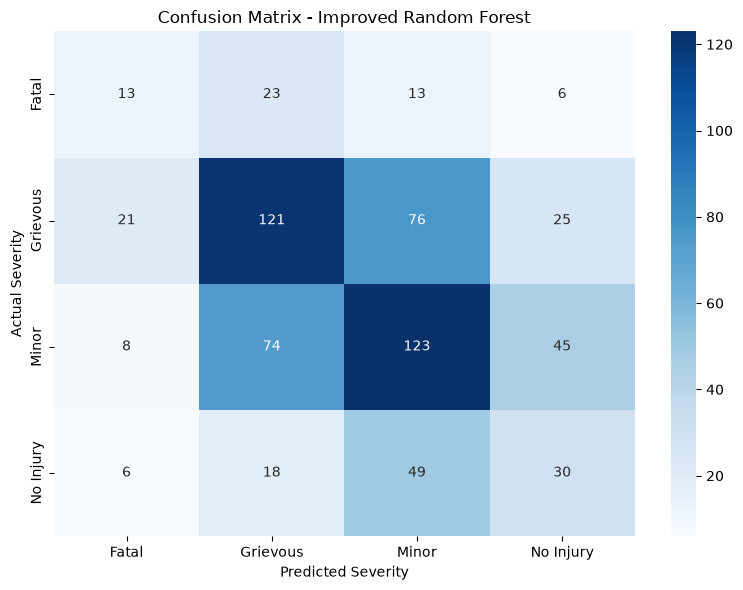

Confusion matrix saved successfully!


In [97]:
# Generate and save the confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    confusion_matrix(y_test, y_pred_best),
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Fatal', 'Grievous', 'Minor', 'No Injury'],
    yticklabels=['Fatal', 'Grievous', 'Minor', 'No Injury']
)

plt.xlabel('Predicted Severity')
plt.ylabel('Actual Severity')
plt.title('Confusion Matrix - Improved Random Forest')

plt.tight_layout()
plt.savefig(
    '../outputs/confusion_matrix.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Confusion matrix saved successfully!")

In [101]:
from sklearn.inspection import permutation_importance

permutation_result = permutation_importance(
    rf_balanced_model,
    X_test,
    y_test,
    scoring='f1_macro',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

print("Permutation importance calculated successfully.")

Permutation importance calculated successfully.


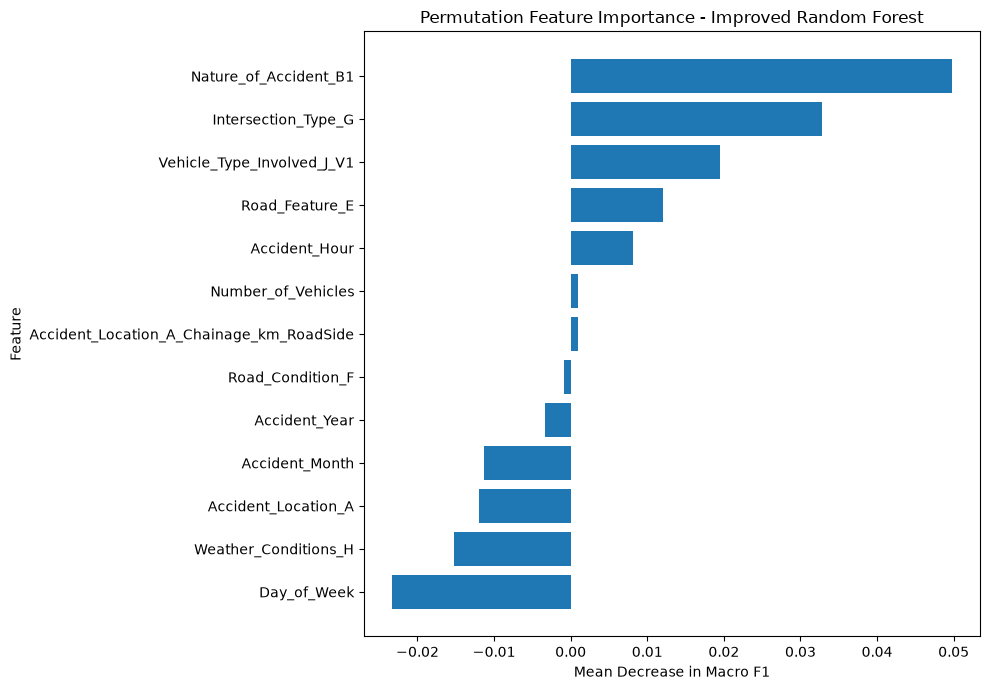

Feature importance chart saved successfully!


In [102]:
# Plot permutation feature importance
plt.figure(figsize=(10, 7))

importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': permutation_result.importances_mean
}).sort_values(by='Importance', ascending=True)

plt.barh(
    importance_df['Feature'],
    importance_df['Importance']
)

plt.xlabel('Mean Decrease in Macro F1')
plt.ylabel('Feature')
plt.title('Permutation Feature Importance - Improved Random Forest')

plt.tight_layout()
plt.savefig(
    '../outputs/feature_importance.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Feature importance chart saved successfully!")

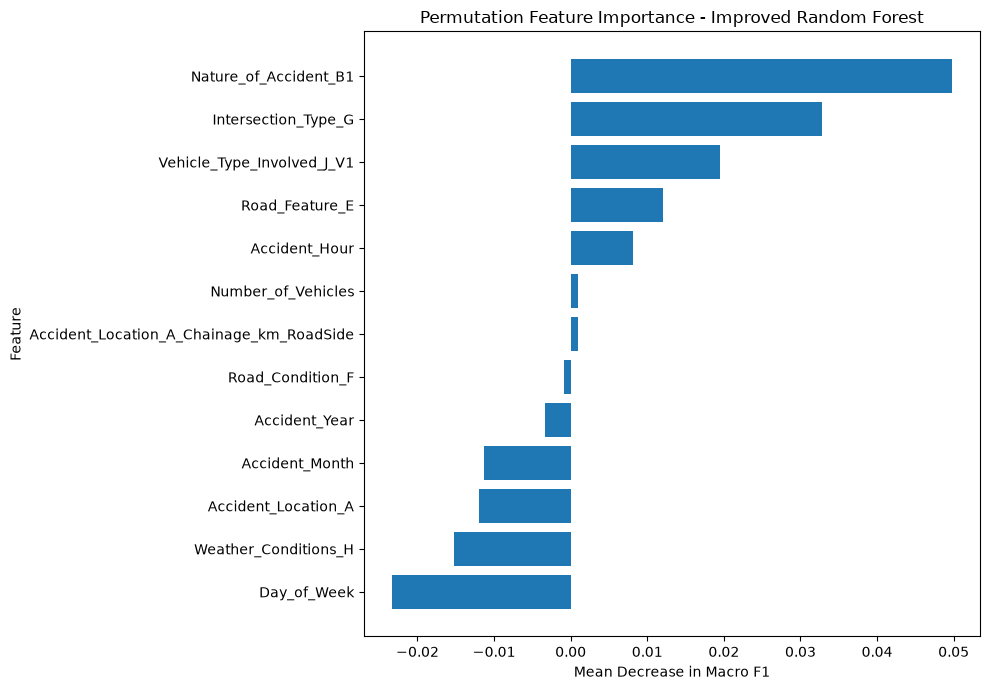

Feature importance chart saved successfully!


In [100]:
importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': permutation_result.importances_mean
}).sort_values(by='Importance', ascending=True)

plt.figure(figsize=(10, 7))

plt.barh(
    importance_df['Feature'],
    importance_df['Importance']
)

plt.xlabel('Mean Decrease in Macro F1')
plt.ylabel('Feature')
plt.title('Permutation Feature Importance - Improved Random Forest')

plt.tight_layout()

plt.savefig(
    '../outputs/feature_importance.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Feature importance chart saved successfully!")

In [103]:
from pathlib import Path
import joblib

# Create models folder
model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

# Save all four trained models
models = {
    "decision_tree.pkl": decision_tree_model,
    "random_forest.pkl": random_forest_model,
    "gradient_boosting.pkl": gradient_boosting_model,
    "improved_random_forest.pkl": rf_balanced_model
}

for filename, trained_model in models.items():
    joblib.dump(trained_model, model_dir / filename)
    print(f"Saved: {filename}")

print("\nAll four models saved successfully!")

Saved: decision_tree.pkl
Saved: random_forest.pkl
Saved: gradient_boosting.pkl
Saved: improved_random_forest.pkl

All four models saved successfully!
